# Подробный EDA госпитализаций пациентов с диабетом

**Авторы:** Zhenissov Kaiyrbek и Bekarys.

Одна строка — одна госпитализация. Цель — зарегистрированная повторная госпитализация **менее чем через 30 дней**. Прогноз делается при выписке. Источник: [UCI](https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008), CC BY 4.0.

Сначала проверяем весь источник. Затем исключаем исходы смерти/хосписа по заранее заданной популяции и делим пациентов на fit/calibration/validation/test. Все связи признаков с целью ниже относятся **только к fit**. Код расчёта графиков находится в `src/eda.py`; ноутбук объединяет исходные проверки, результаты и объяснения.

Перед первым запуском: `python main.py all`. Для воспроизведения только EDA: `python main.py eda`. Весь источник меньше рекомендуемых 500 тыс. строк / 200 МБ; исключение следует согласовать с преподавателем.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
if not (ROOT / 'src').exists(): ROOT = ROOT.parent
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
import pandas as pd
import numpy as np
from IPython.display import display, Image, Markdown
from src.config import *
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 60)
def table(name): return pd.read_csv(TABLES / name)
def figure(name, width=1000): display(Image(filename=str(FIGURES / name), width=width))


## 1 Загрузка и структура
Читаем ZIP без распаковки. Сохраняем категорию None, а ? и пустые поля считаем пропусками.

In [2]:
from src.data import load_data, make_cohort, patient_split, optimize_types
raw, mappings, source_info = load_data()
cohort, flow = make_cohort(raw)
parts = patient_split(cohort)
fit = parts['fit'].copy()
print(raw.shape)
display(raw.head())
raw.info(memory_usage='deep')

(101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),<NA>,6,25,1,1,<NA>,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,<NA>,<NA>,1,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),<NA>,1,1,7,3,<NA>,<NA>,59,0,18,0,0,0,276,250.01,255,9,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),<NA>,1,1,7,2,<NA>,<NA>,11,5,13,2,0,1,648,250,V27,6,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),<NA>,1,1,7,2,<NA>,<NA>,44,1,16,0,0,0,8,250.43,403,7,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),<NA>,1,1,7,1,<NA>,<NA>,51,0,8,0,0,0,197,157,250,5,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      99493 non-null   string
 3   gender                    101766 non-null  string
 4   age                       101766 non-null  string
 5   weight                    3197 non-null    string
 6   admission_type_id         101766 non-null  string
 7   discharge_disposition_id  101766 non-null  string
 8   admission_source_id       101766 non-null  string
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                61510 non-null   string
 11  medical_specialty         51817 non-null   string
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_medications

## 2 Паспорт всех 50 столбцов
Кардинальность и доминирующее значение — диагностические признаки, а не автоматические критерии удаления.

In [3]:
display(pd.read_csv(TABLES/'source_column_audit.csv', index_col=0).round(3))

,dtype,missing_count,missing_pct,unique,dominant_pct
encounter_id,int64,0,0.000,101766,0.001
patient_nbr,int64,0,0.000,71518,0.039
race,string,2273,2.234,5,74.778
gender,string,0,0.000,3,53.759
age,string,0,0.000,10,25.616
weight,string,98569,96.858,9,96.858
admission_type_id,string,0,0.000,8,53.053
discharge_disposition_id,string,0,0.000,26,59.189
admission_source_id,string,0,0.000,17,56.496
time_in_hospital,int64,0,0.000,14,17.448


## 3 Ключи и повторные пациенты
encounter_id должен быть уникальным. Повторение patient_nbr означает разные госпитализации и не является дубликатом. Общее число госпитализаций пациента не используем как вход модели: оно может учитывать будущее.

,value
duplicate_rows,0
duplicate_encounter_id,0
patients,71518
repeat_patients,16773
max_encounters,40


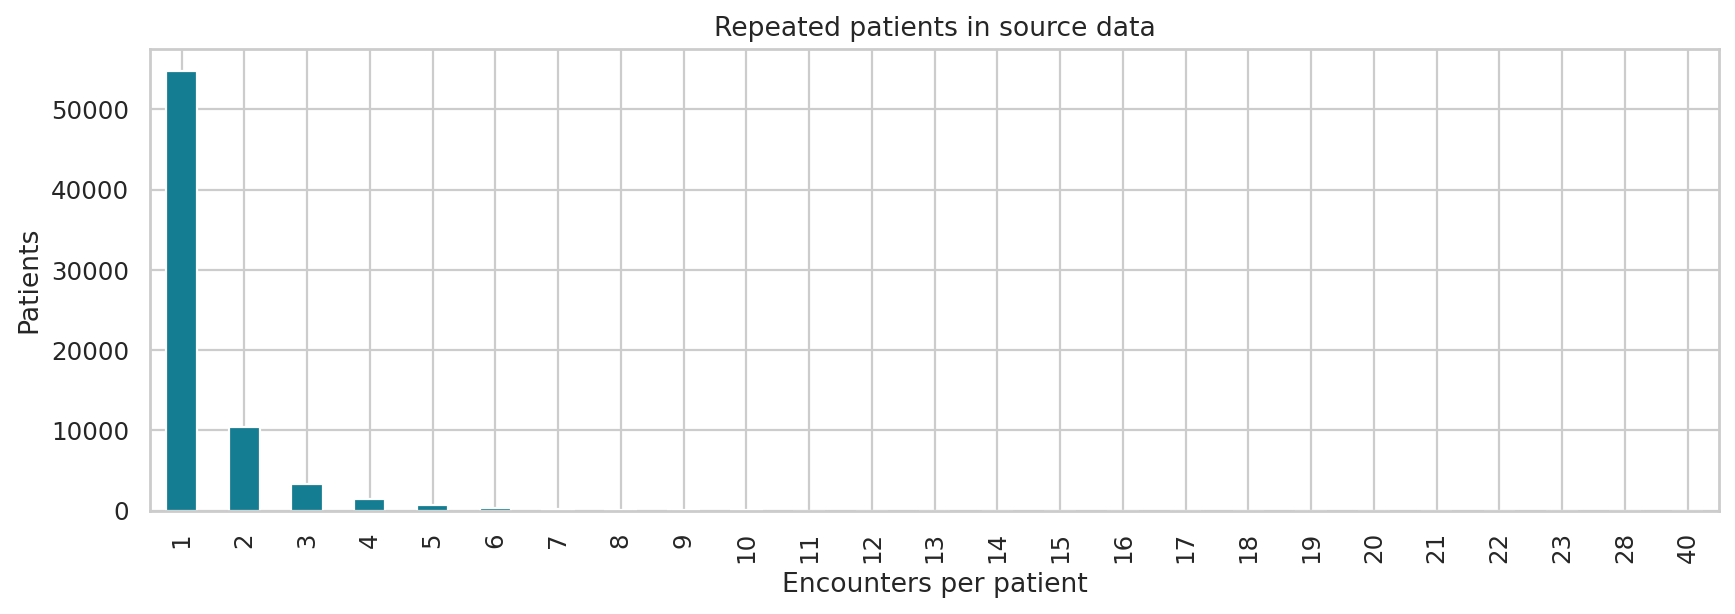

In [4]:
counts = raw.groupby('patient_nbr').size()
display(pd.Series({'duplicate_rows':raw.duplicated().sum(),'duplicate_encounter_id':raw.encounter_id.duplicated().sum(),'patients':len(counts),'repeat_patients':counts.gt(1).sum(),'max_encounters':counts.max()}).to_frame('value'))
figure('02_patient_recurrence.png')

## 4 Цель и популяция
<30 → 1; >30 и NO → 0. NO означает отсутствие зарегистрированного повторного обращения в источнике. Смерть и хоспис исключены до разбиения. Повторные госпитализации остальных пациентов сохраняются.

,readmitted,encounters
0,NO,54864
1,>30,35545
2,<30,11357


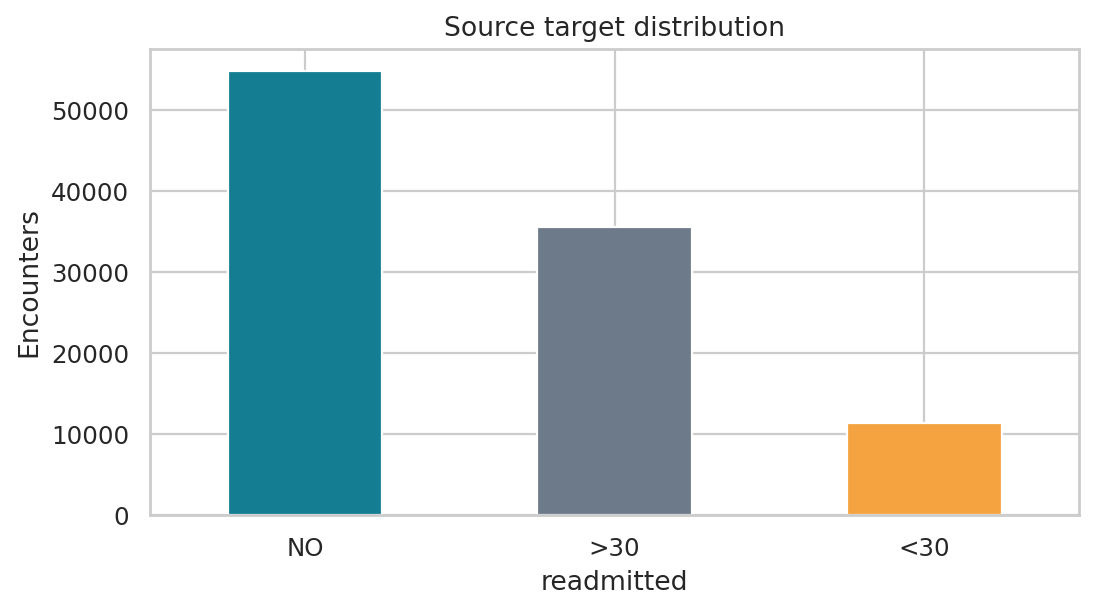

,value
raw_encounters,101766
raw_patients,71518
death_encounters,1652
hospice_encounters,771
cohort_encounters,99343
cohort_patients,69990
cohort_positive,11314


,split,encounters,patients,positives,positive_rate
0,fit,59735,41994,6855,0.114757
1,calibration,9898,6999,1179,0.119115
2,validation,9908,6999,1064,0.107388
3,test,19802,13998,2216,0.111908


In [5]:
display(table('raw_target.csv'))
figure('01_target_balance.png',700)
display(pd.Series(flow).to_frame('value'))
display(table('split_summary.csv'))
assert all(set(a.patient_nbr).isdisjoint(b.patient_nbr) for na,a in parts.items() for nb,b in parts.items() if na!=nb)

## 5 Пропуски
Неизвестные коды тоже учитываются. None в лабораторных результатах — осмысленная категория отсутствия исследования. Тип пропусков MCAR/MAR/MNAR по одним частотам не устанавливаем.

,Unnamed: 0,count,percent
0,weight,57864,96.868
1,medical_specialty,29240,48.950
2,payer_code,23576,39.468
3,admission_type_id,6096,10.205
4,admission_source_id,4150,6.947
5,discharge_disposition_id,2793,4.676
6,race,1355,2.268
7,diag_3,880,1.473
8,diag_2,209,0.350
9,diag_1,10,0.017


,Unnamed: 0,0,1
0,race,2.337,1.736
1,gender,0.004,0.000
2,age,0.000,0.000
3,weight,96.861,96.922
4,admission_type_id,10.280,9.628
5,discharge_disposition_id,4.707,4.435
6,admission_source_id,6.993,6.594
7,time_in_hospital,0.000,0.000
8,payer_code,39.348,40.394
9,medical_specialty,48.669,51.116


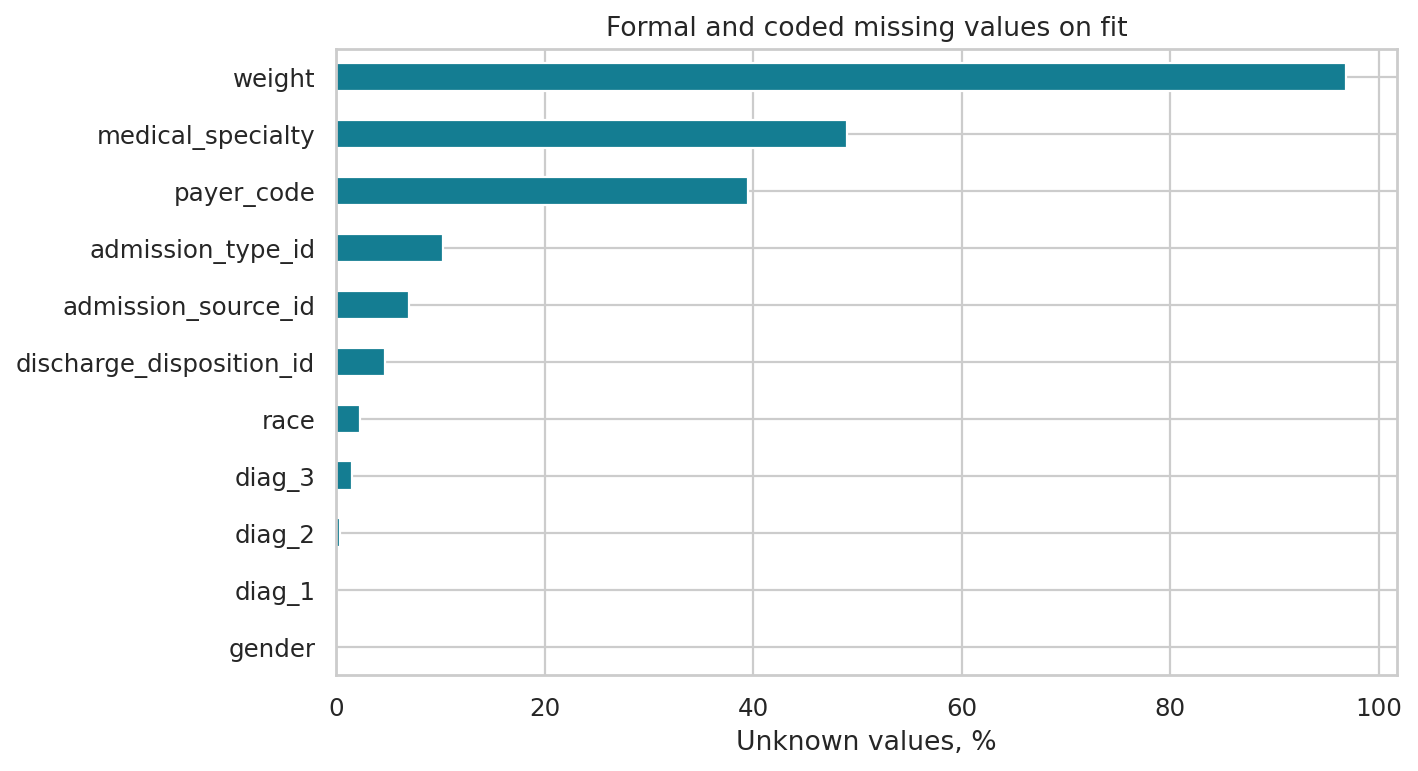

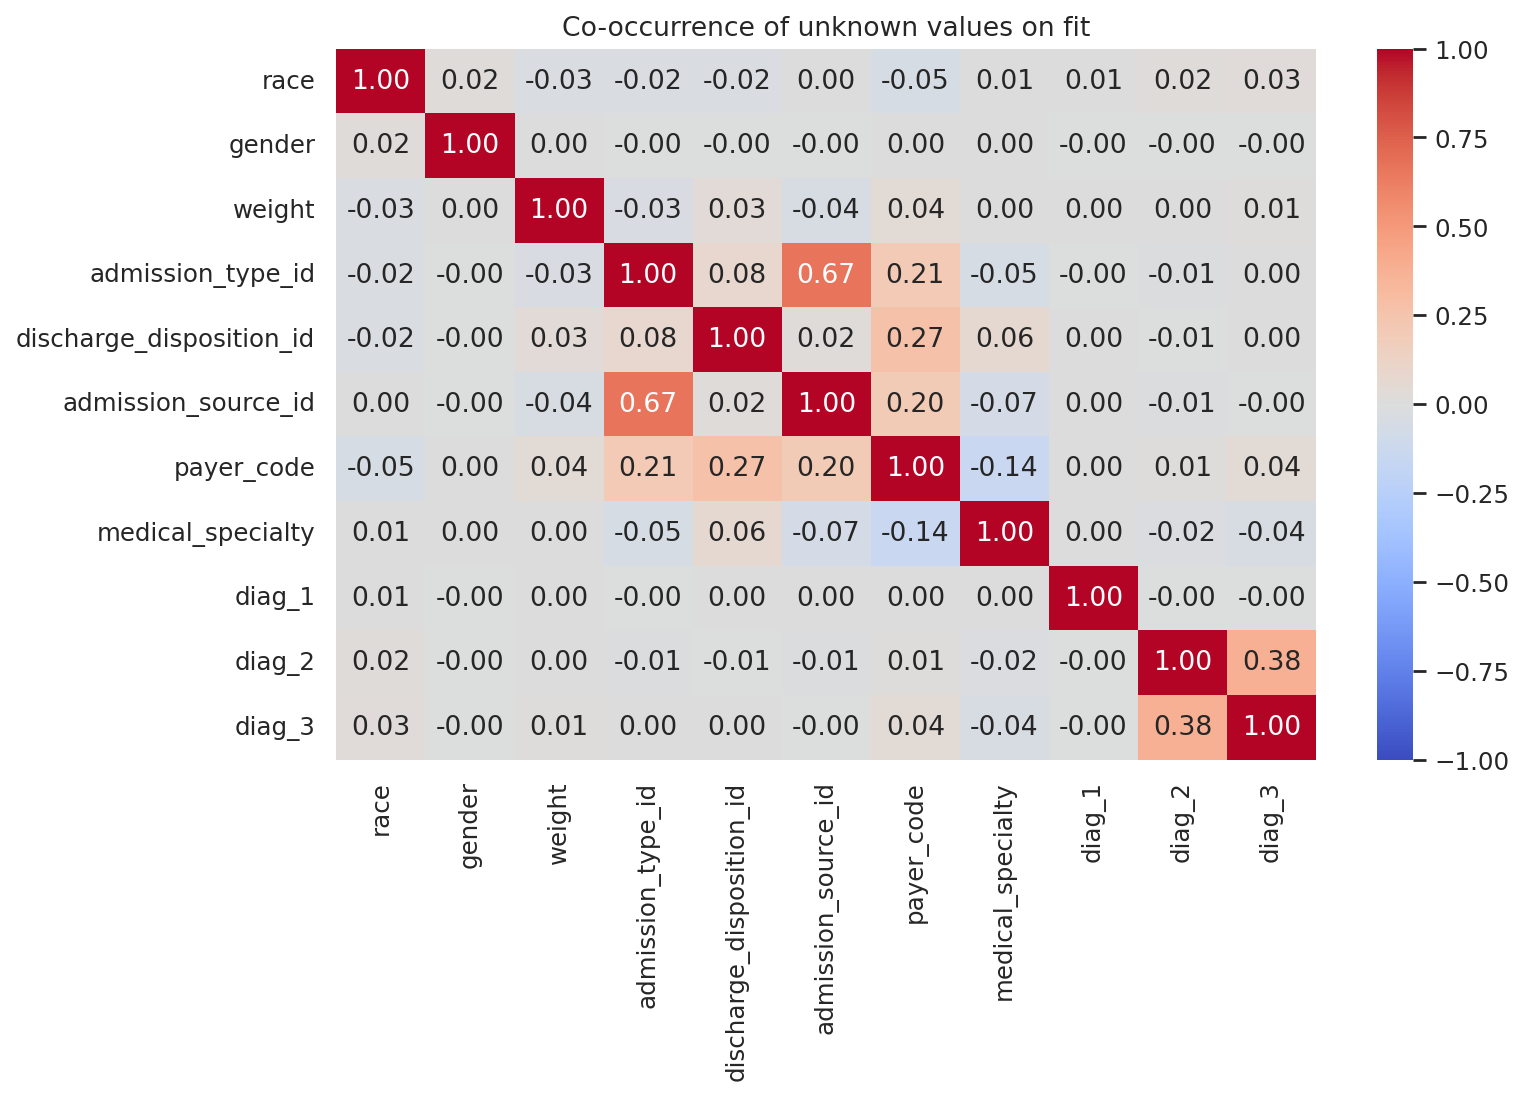

In [6]:
display(table('fit_missingness.csv').round(3))
display(table('missingness_by_target.csv').round(3))
figure('03_missing_values.png')
figure('04_missingness_correlation.png')

## 6 Количественные признаки
Разбираем все восемь показателей: время в стационаре, лабораторные и другие процедуры, препараты, амбулаторные/экстренные/стационарные обращения за предшествующий год и число диагнозов. Коды и идентификаторы в числовую статистику не включены.

,Unnamed: 0,count,mean,std,min,1%,25%,50%,75%,95%,99%,max,zero_pct
0,time_in_hospital,59735.0,4.370,2.954,1.0,1.0,2.0,4.0,6.0,11.0,13.0,14.0,0.000
1,num_lab_procedures,59735.0,42.906,19.568,1.0,1.0,31.0,44.0,57.0,73.0,84.0,132.0,0.000
2,num_procedures,59735.0,1.332,1.700,0.0,0.0,0.0,1.0,2.0,5.0,6.0,6.0,46.132
3,num_medications,59735.0,15.972,8.128,1.0,3.0,10.0,15.0,20.0,31.0,43.0,81.0,0.000
4,number_outpatient,59735.0,0.360,1.210,0.0,0.0,0.0,0.0,0.0,2.0,5.0,40.0,83.589
5,number_emergency,59735.0,0.205,1.009,0.0,0.0,0.0,0.0,0.0,1.0,3.0,76.0,88.657
6,number_inpatient,59735.0,0.632,1.240,0.0,0.0,0.0,0.0,1.0,3.0,6.0,16.0,66.529
7,number_diagnoses,59735.0,7.394,1.946,1.0,2.0,6.0,8.0,9.0,9.0,9.0,16.0,0.000


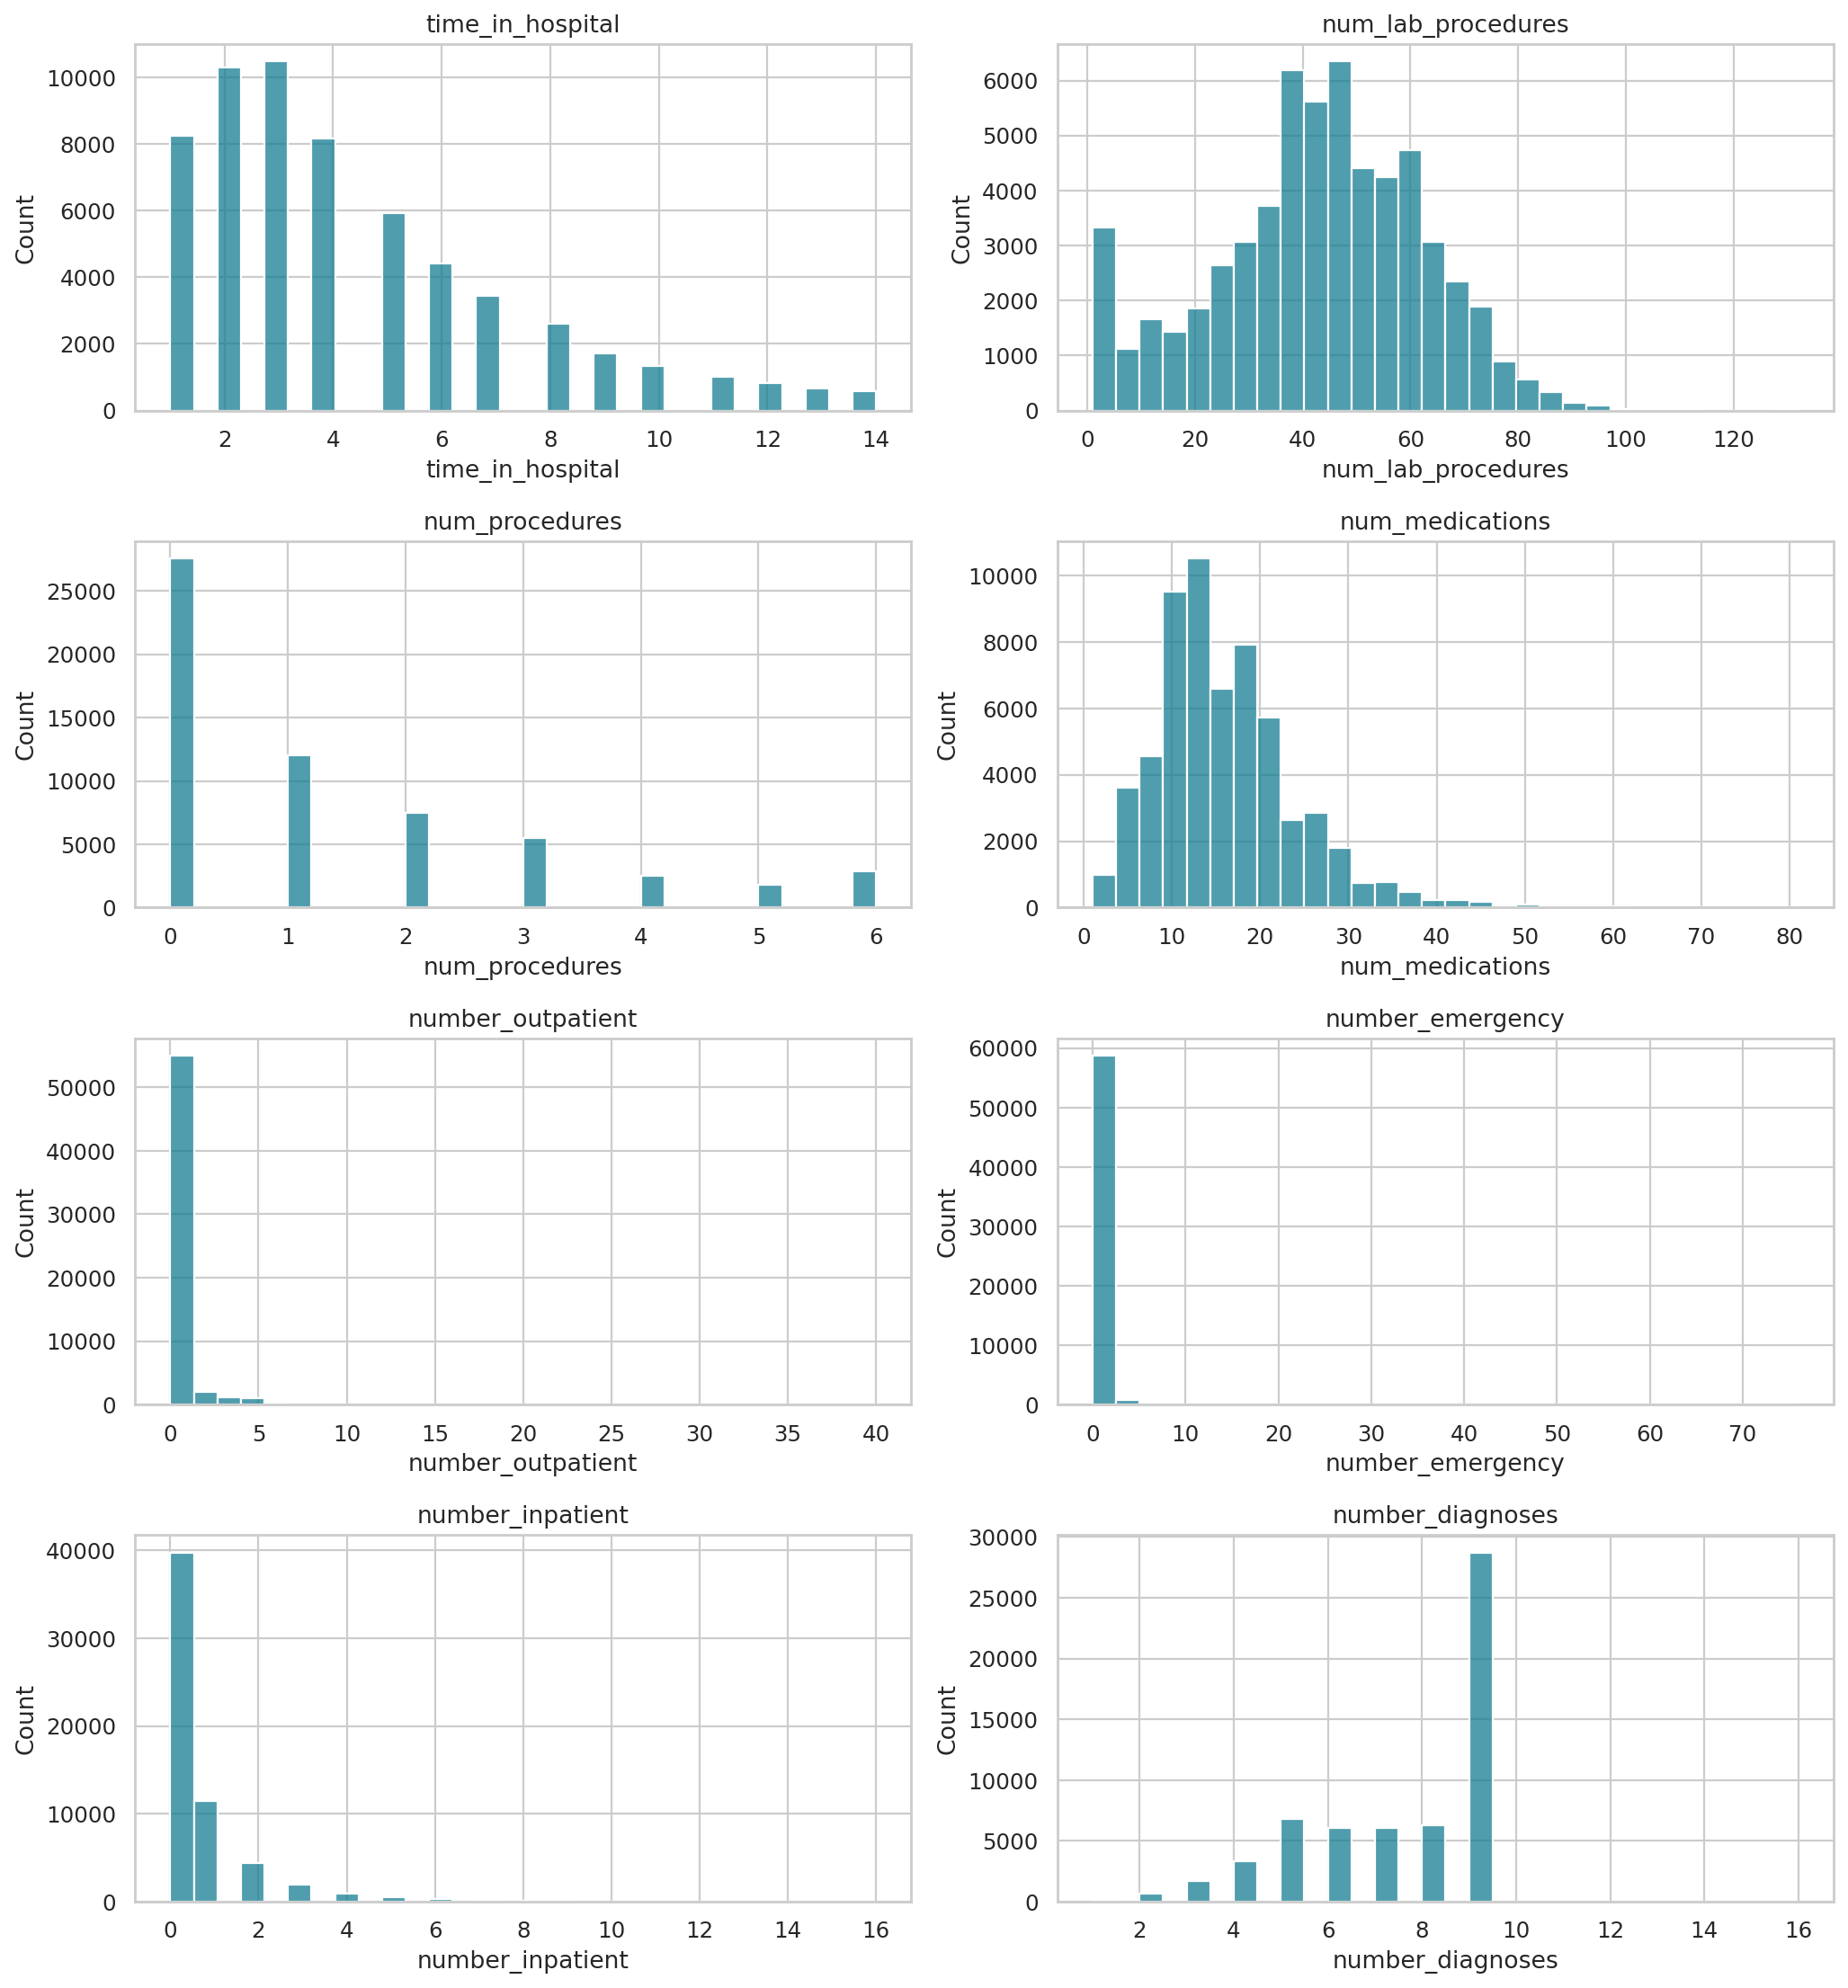

,Unnamed: 0,Unnamed: 1,0,1
0,time_in_hospital,mean,4.315790,4.788330
1,time_in_hospital,median,4.000000,4.000000
2,time_in_hospital,std,2.938522,3.037214
3,num_lab_procedures,mean,42.742190,44.171116
4,num_lab_procedures,median,44.000000,45.000000
5,num_lab_procedures,std,19.600713,19.272728
6,num_procedures,mean,1.339523,1.272210
7,num_procedures,median,1.000000,1.000000
8,num_procedures,std,1.707735,1.640958
9,num_medications,mean,15.847334,16.931291


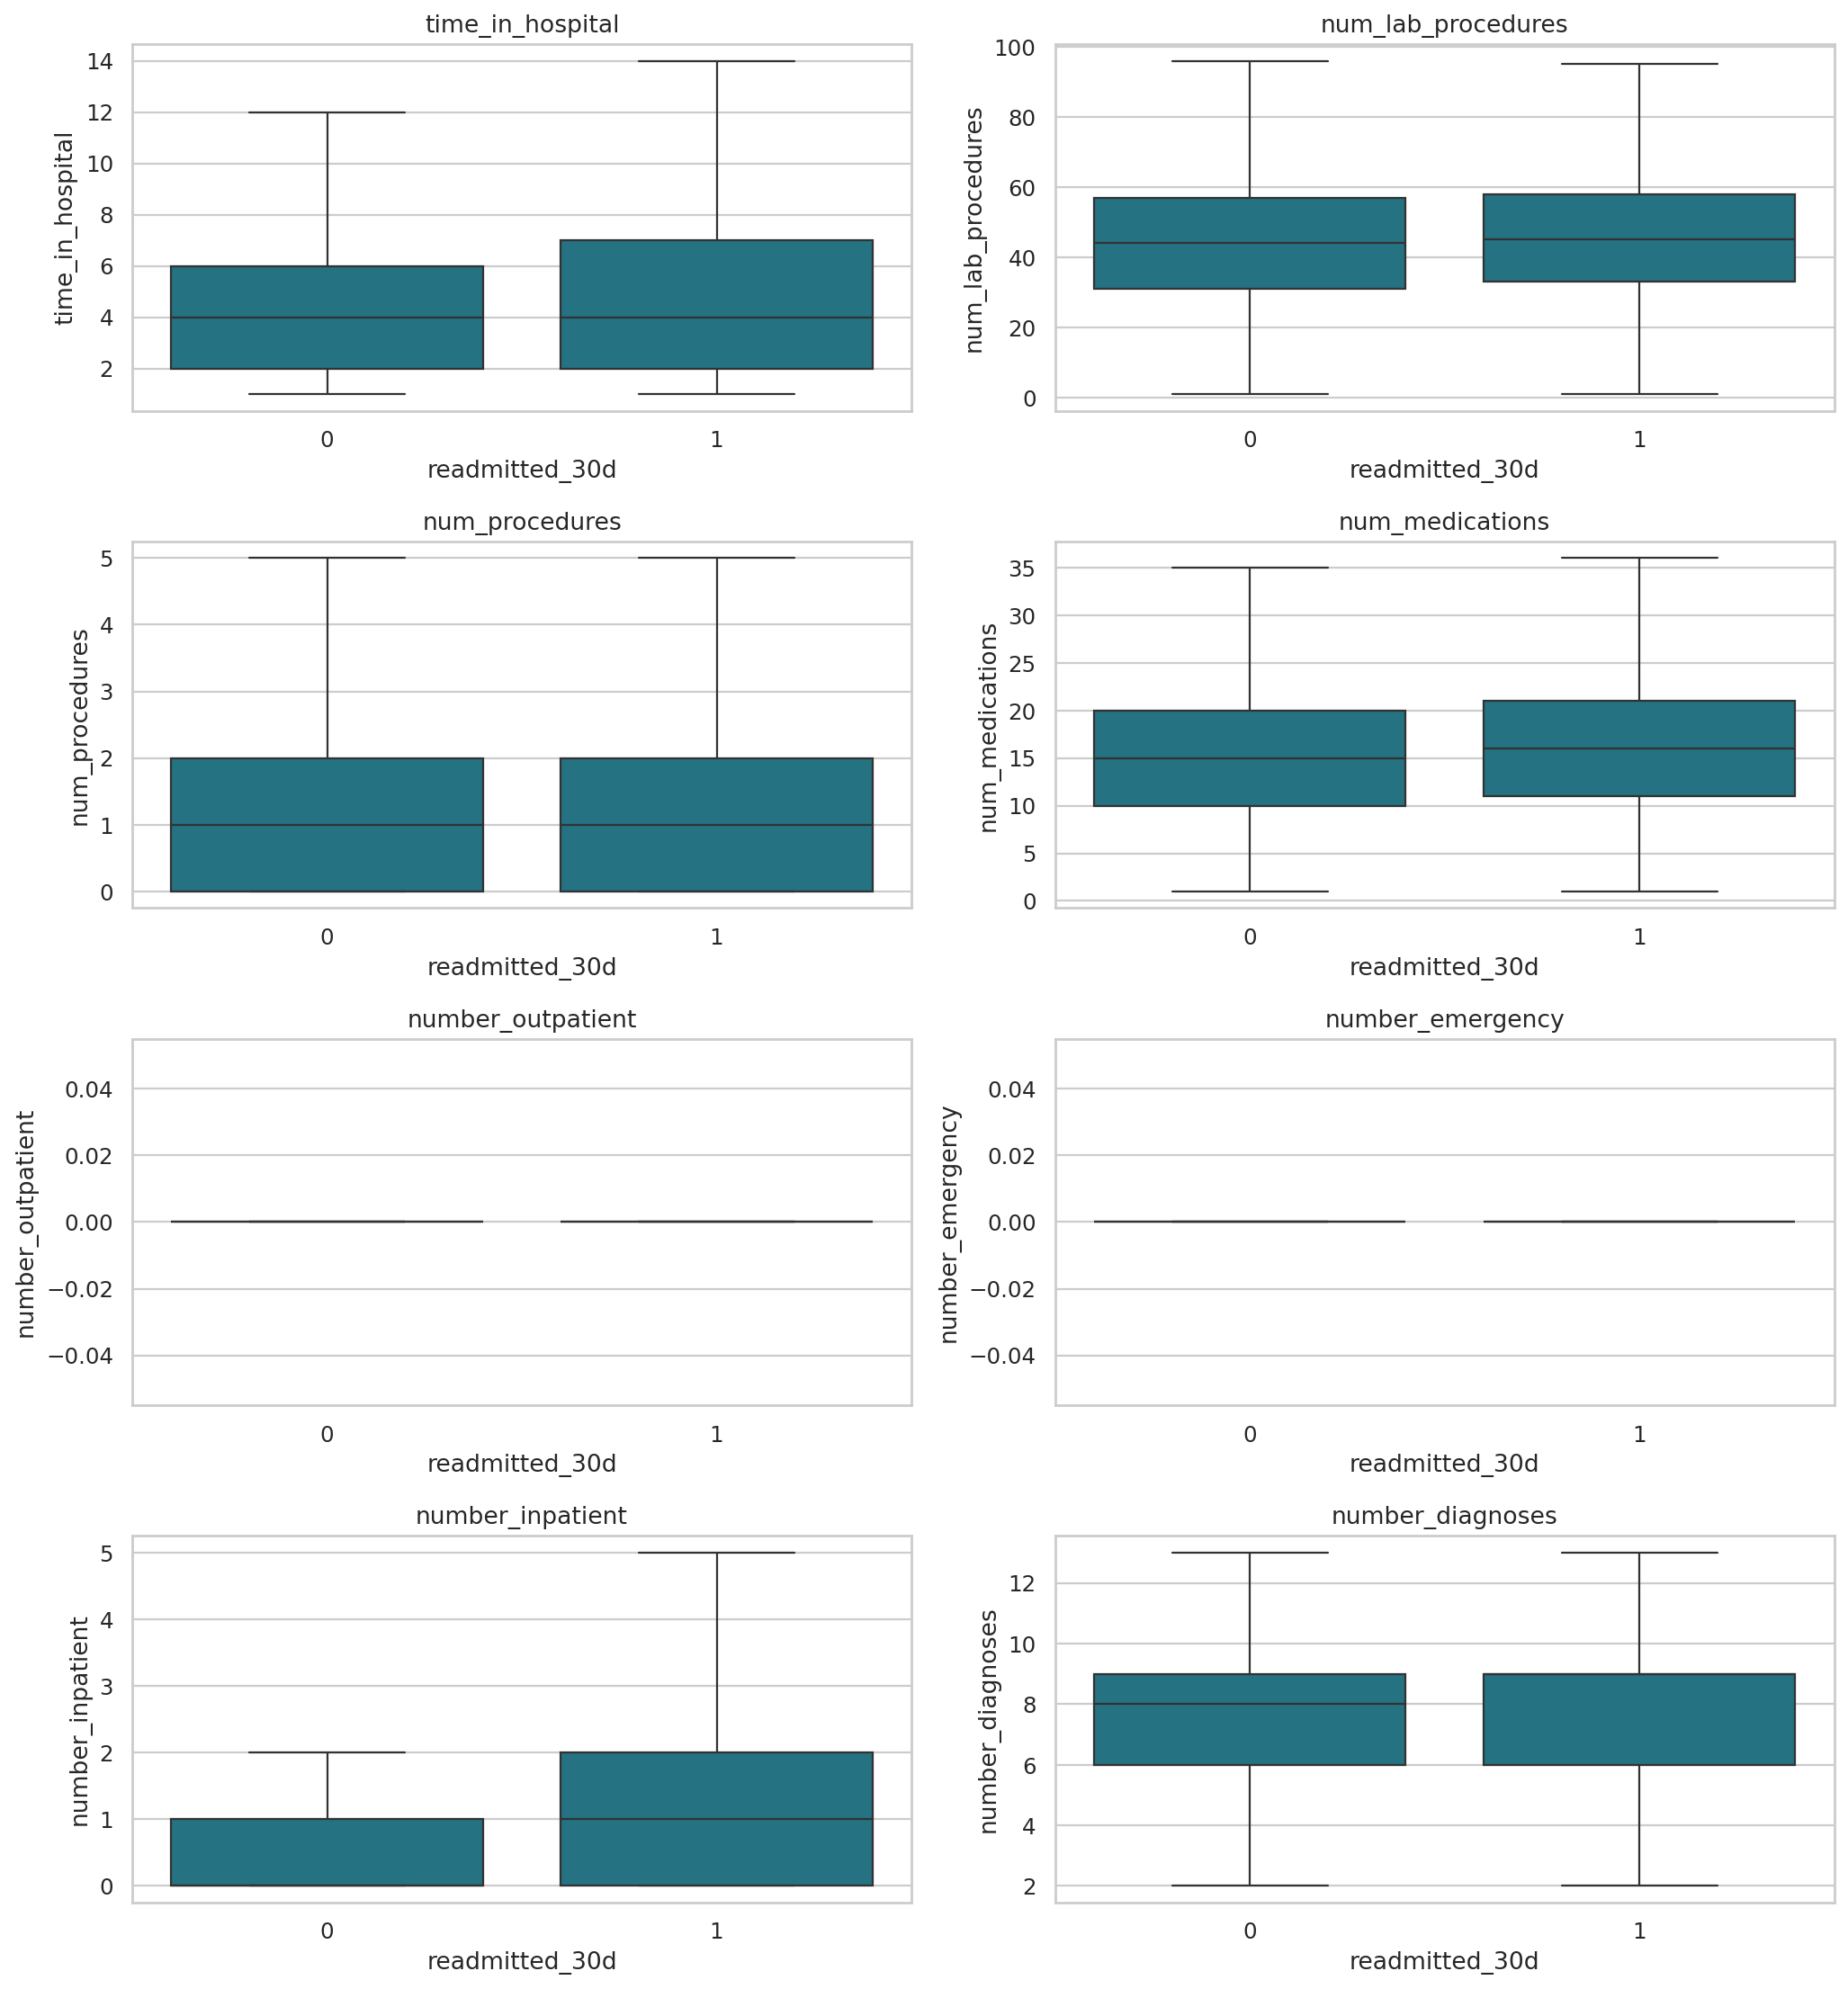

In [7]:
display(table('numeric_descriptive.csv').round(3))
figure('05_numeric_distributions.png')
display(table('numeric_by_target.csv'))
figure('06_numeric_by_target.png')

## 7 Выбросы
Граница 1.5 IQR — диагностический флаг, а не доказательство ошибки. При IQR=0 ненулевые обращения могут формально стать выбросами. Наблюдения не удаляются. В boxplot крайние точки скрыты только для читаемости.

In [8]:
display(table('outlier_diagnostics.csv').round(3))

,Unnamed: 0,q1,q3,iqr,outside_pct,maximum,note
0,time_in_hospital,2.0,6.0,4.0,2.094,14,Diagnostic only
1,num_lab_procedures,31.0,57.0,26.0,0.105,132,Diagnostic only
2,num_procedures,0.0,2.0,2.0,4.744,6,Diagnostic only
3,num_medications,10.0,20.0,10.0,2.488,81,Diagnostic only
4,number_outpatient,0.0,0.0,0.0,16.411,40,IQR=0; do not auto-delete
5,number_emergency,0.0,0.0,0.0,11.343,76,IQR=0; do not auto-delete
6,number_inpatient,0.0,1.0,1.0,6.946,16,Diagnostic only
7,number_diagnoses,6.0,9.0,3.0,0.275,16,Diagnostic only


## 8 Демография и административные признаки
Показываем число госпитализаций, число пациентов и долю <30 внутри каждой категории. Малые группы не интерпретируем как надёжные различия риска. weight почти пустой; в первой модели используем только индикатор наличия записи.

### race

,category,encounters,patients,positives,share_pct,readmission_pct
0,Caucasian,44534,31433,5144,74.553,11.551
1,AfricanAmerican,11362,7628,1325,19.021,11.662
2,Missing,1355,1175,119,2.268,8.782
3,Hispanic,1229,912,134,2.057,10.903
4,Other,870,696,90,1.456,10.345
5,Asian,385,307,43,0.645,11.169


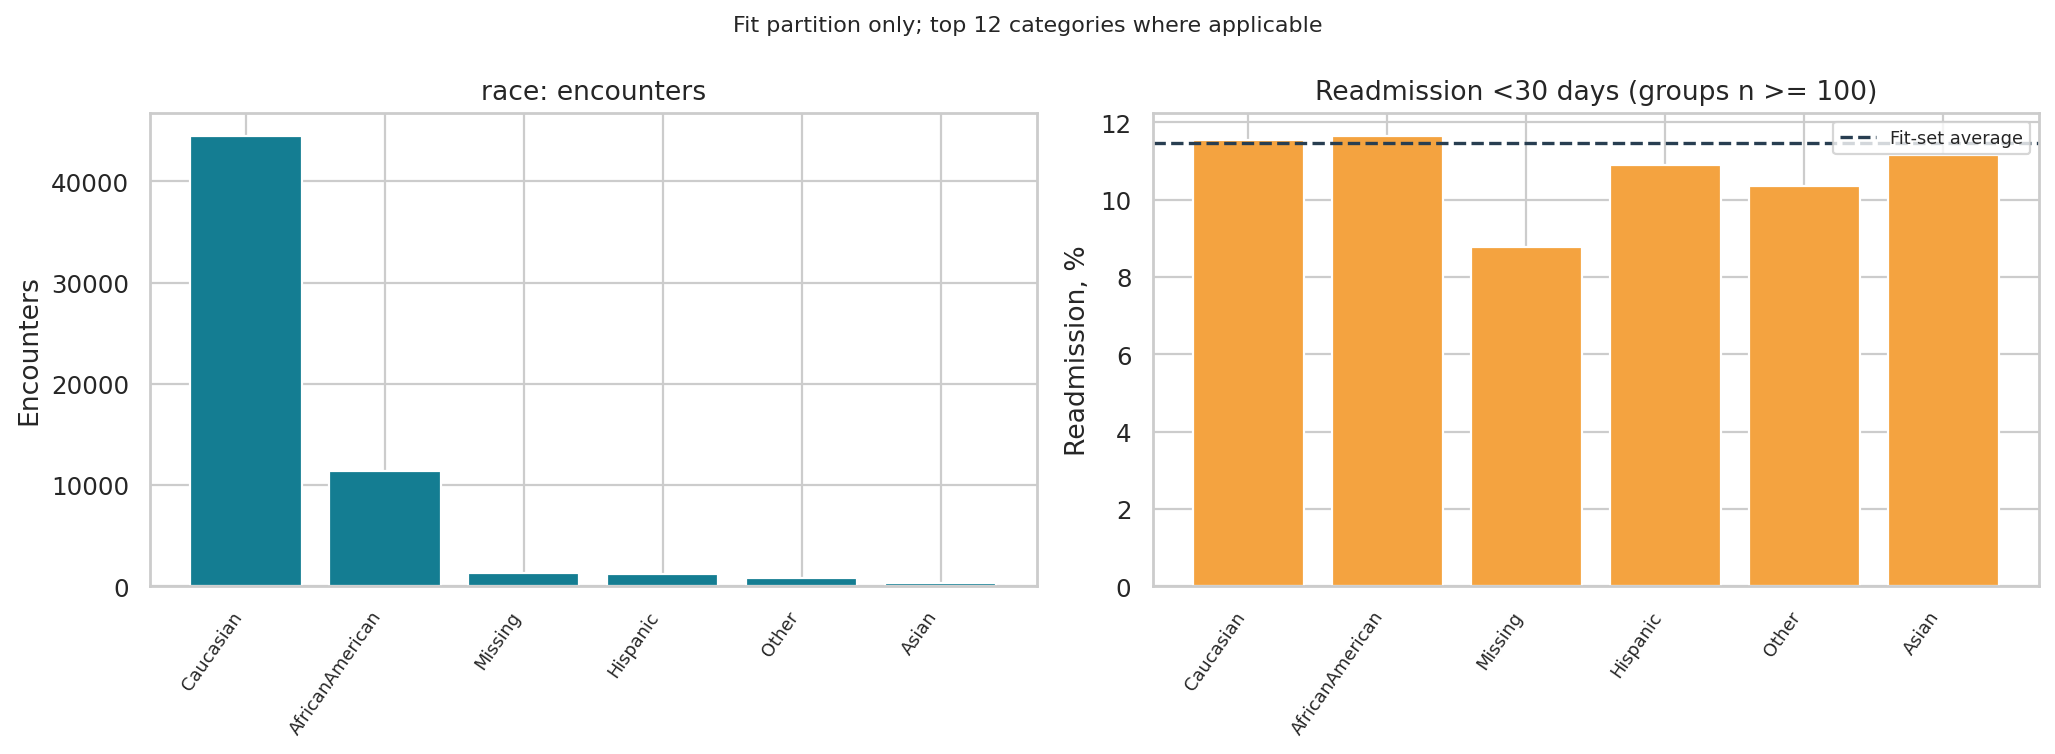

### gender

,category,encounters,patients,positives,share_pct,readmission_pct
0,Female,32227,22357,3724,53.950,11.556
1,Male,27506,19638,3131,46.047,11.383
2,Unknown/Invalid,2,2,0,0.003,0.000


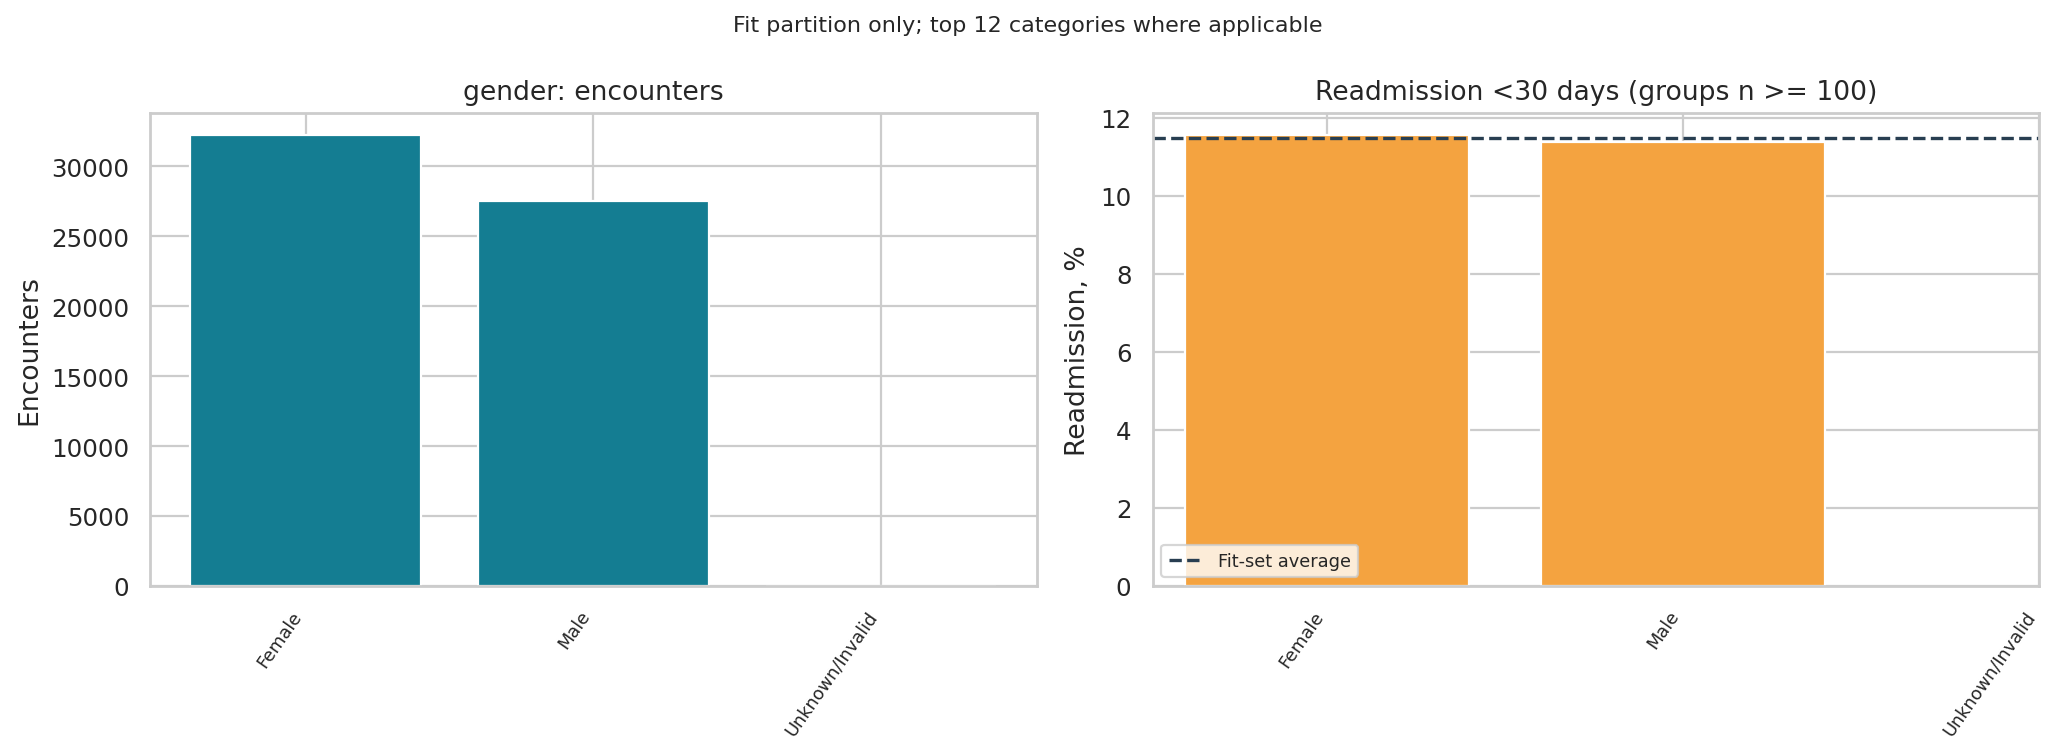

### age

,category,encounters,patients,positives,share_pct,readmission_pct
0,[70-80),15258,10906,1863,25.543,12.210
1,[60-70),13237,9620,1490,22.160,11.256
2,[50-60),10310,7535,1002,17.260,9.719
3,[80-90),9852,6910,1272,16.493,12.911
4,[40-50),5861,4165,642,9.812,10.954
5,[30-40),2233,1584,260,3.738,11.644
6,[90-100),1526,1130,171,2.555,11.206
7,[20-30),940,658,129,1.574,13.723
8,[10-20),415,321,26,0.695,6.265
9,[0-10),103,100,0,0.172,0.000


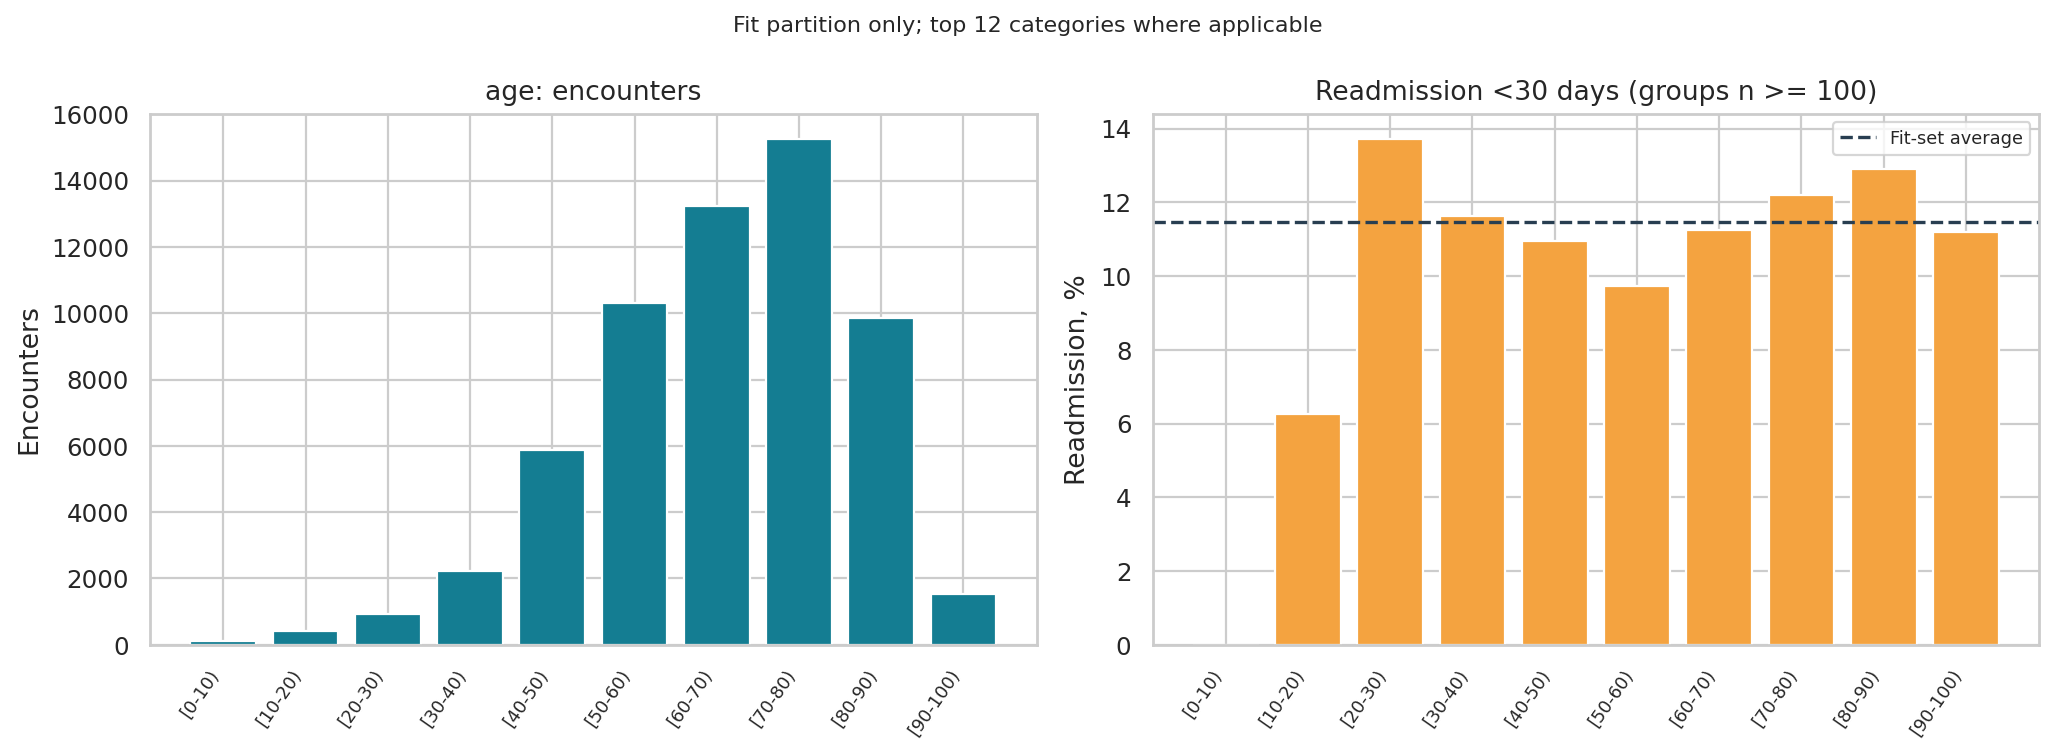

### weight

,category,encounters,patients,positives,share_pct,readmission_pct
0,Missing,57864,40320,6644,96.868,11.482
1,[75-100),793,733,91,1.328,11.475
2,[50-75),509,468,62,0.852,12.181
3,[100-125),362,344,40,0.606,11.050
4,[125-150),89,86,7,0.149,7.865
5,[25-50),55,54,5,0.092,9.091
6,[0-25),32,32,4,0.054,12.500
7,[150-175),20,20,1,0.033,5.000
8,[175-200),9,8,1,0.015,11.111
9,>200,2,2,0,0.003,0.000


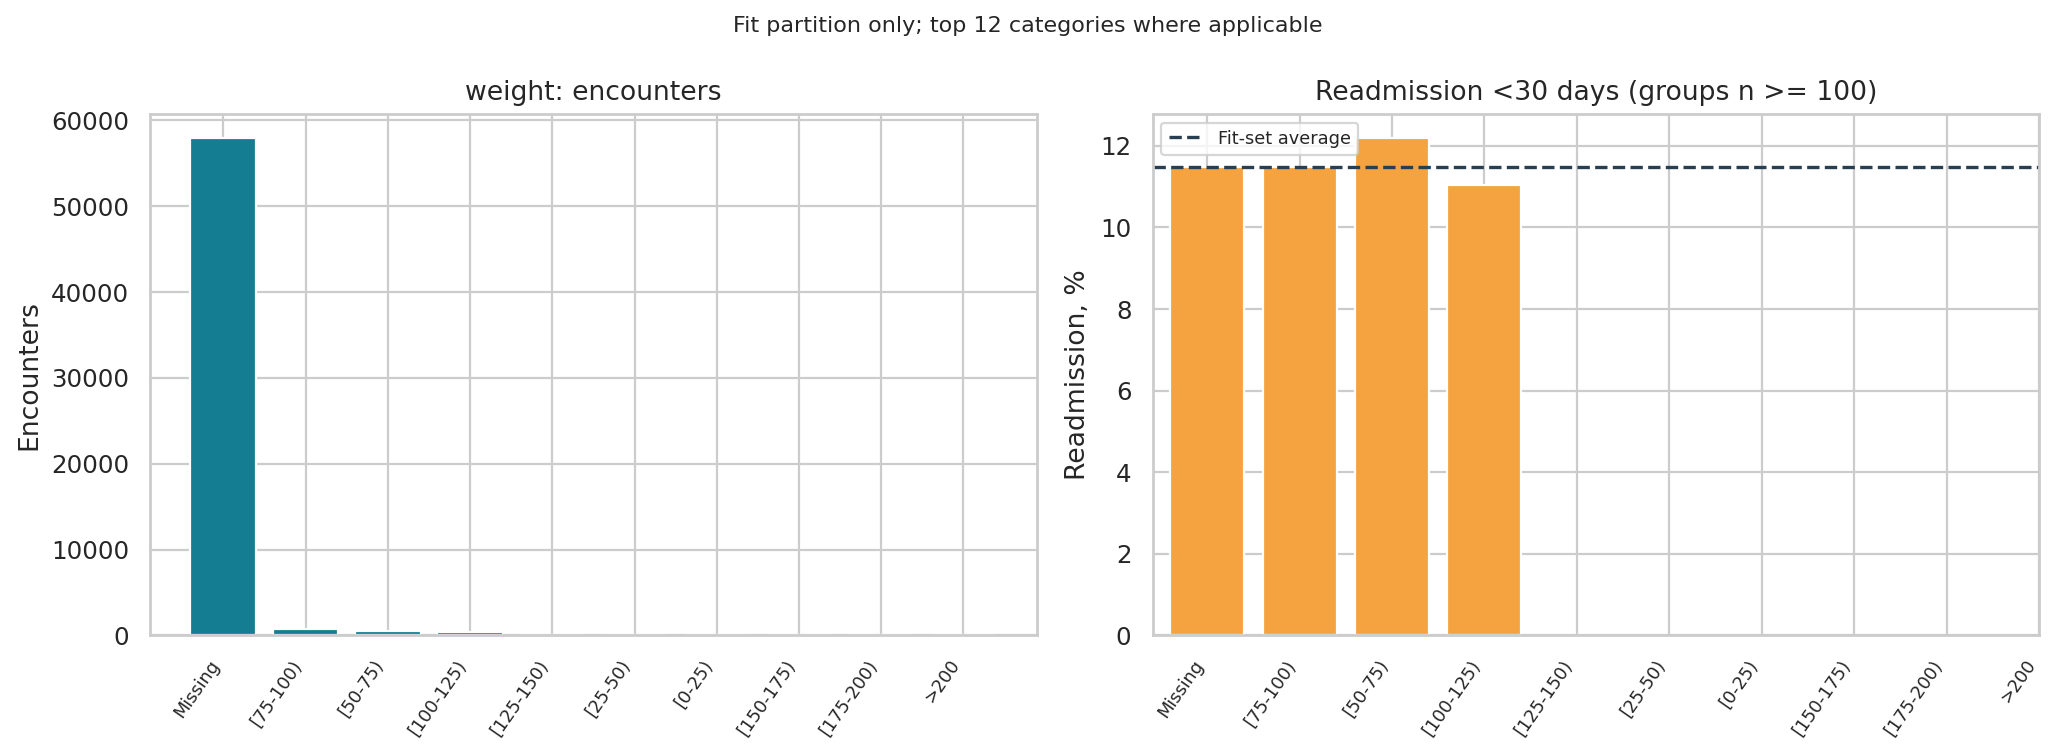

### payer_code

,category,encounters,patients,positives,share_pct,readmission_pct
0,Missing,23576,18269,2769,39.468,11.745
1,MC,18744,12748,2278,31.379,12.153
2,HM,3748,2588,385,6.274,10.272
3,SP,2892,2251,307,4.841,10.615
4,BC,2830,2170,282,4.738,9.965
5,MD,2208,1514,280,3.696,12.681
6,CP,1489,1253,123,2.493,8.261
7,UN,1454,1271,133,2.434,9.147
8,CM,1140,895,109,1.908,9.561
9,OG,625,444,85,1.046,13.600


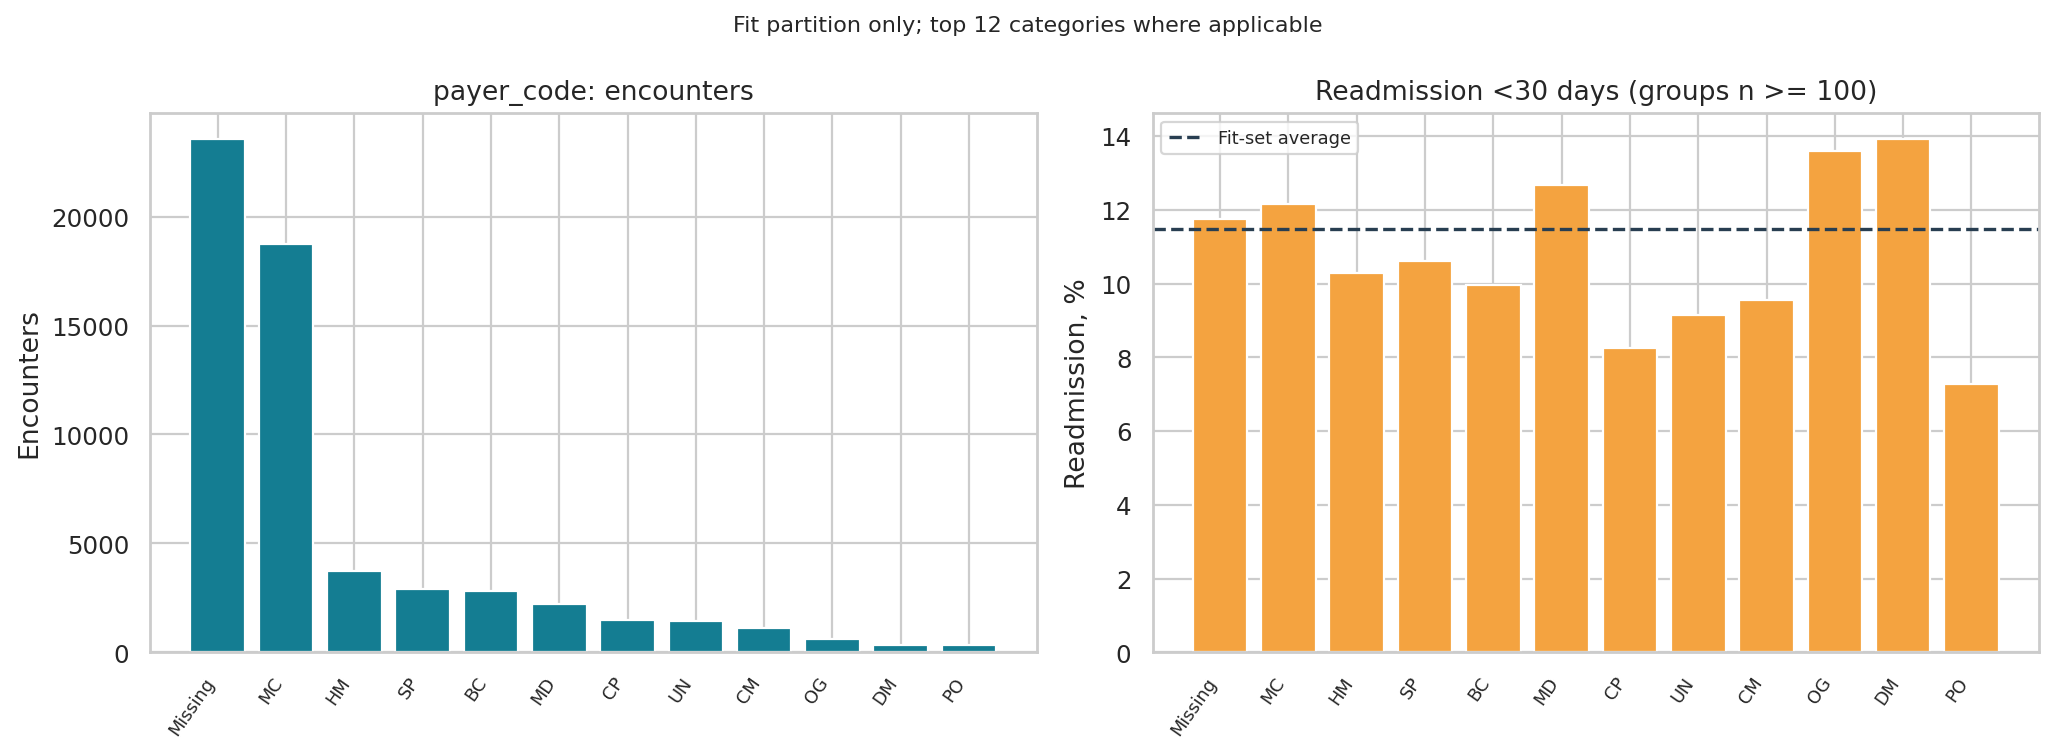

### medical_specialty

,category,encounters,patients,positives,share_pct,readmission_pct
0,Missing,29240,21127,3504,48.950,11.984
1,InternalMedicine,8620,7015,997,14.430,11.566
2,Emergency/Trauma,4496,3037,510,7.527,11.343
3,Family/GeneralPractice,4325,3528,529,7.240,12.231
4,Cardiology,3188,2850,259,5.337,8.124
5,Surgery-General,1832,1665,200,3.067,10.917
6,Nephrology,911,628,143,1.525,15.697
7,Orthopedics,828,754,77,1.386,9.300
8,Orthopedics-Reconstructive,741,703,56,1.240,7.557
9,Radiologist,660,602,62,1.105,9.394


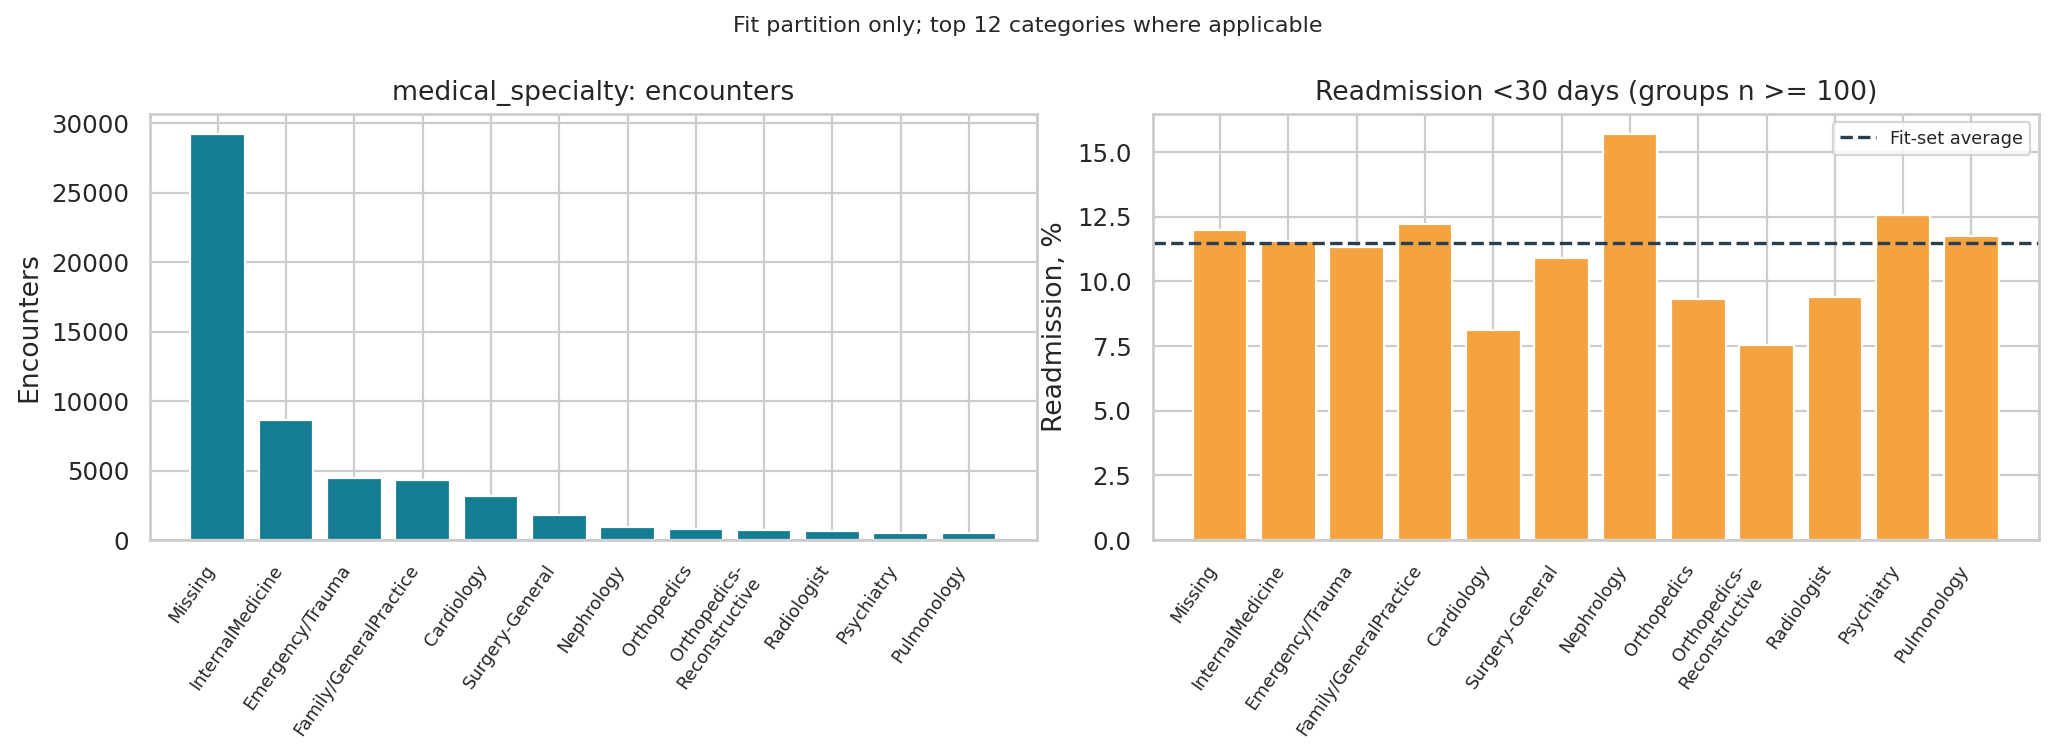

In [9]:
for column in ['race','gender','age','weight','payer_code','medical_specialty']:
    display(Markdown('### '+column))
    display(table('feature_'+column+'.csv').round(3))
    figure('category_'+column+'.png')

## 9 Расшифровки типов поступления и исходов
Все три столбца _id — номинальные категории. Отсутствие NaN не означает полноту информации: существуют коды NULL/Not Available/Unknown. Исход выписки доступен для прогноза при выписке, но недоступен для прогноза при поступлении.

### admission_type_id

,category,encounters,patients,positives,share_pct,readmission_pct,description
0,1,31354,23217,3749,52.488,11.957,Emergency
1,3,11163,9685,1168,18.688,10.463,Elective
2,2,11102,9132,1277,18.585,11.502,Urgent
3,6,3132,2801,347,5.243,11.079,NaN
4,5,2776,1973,295,4.647,10.627,Not Available
5,8,188,187,18,0.315,9.574,Not Mapped
6,7,14,14,0,0.023,0.000,Trauma Center
7,4,6,6,1,0.010,16.667,Newborn


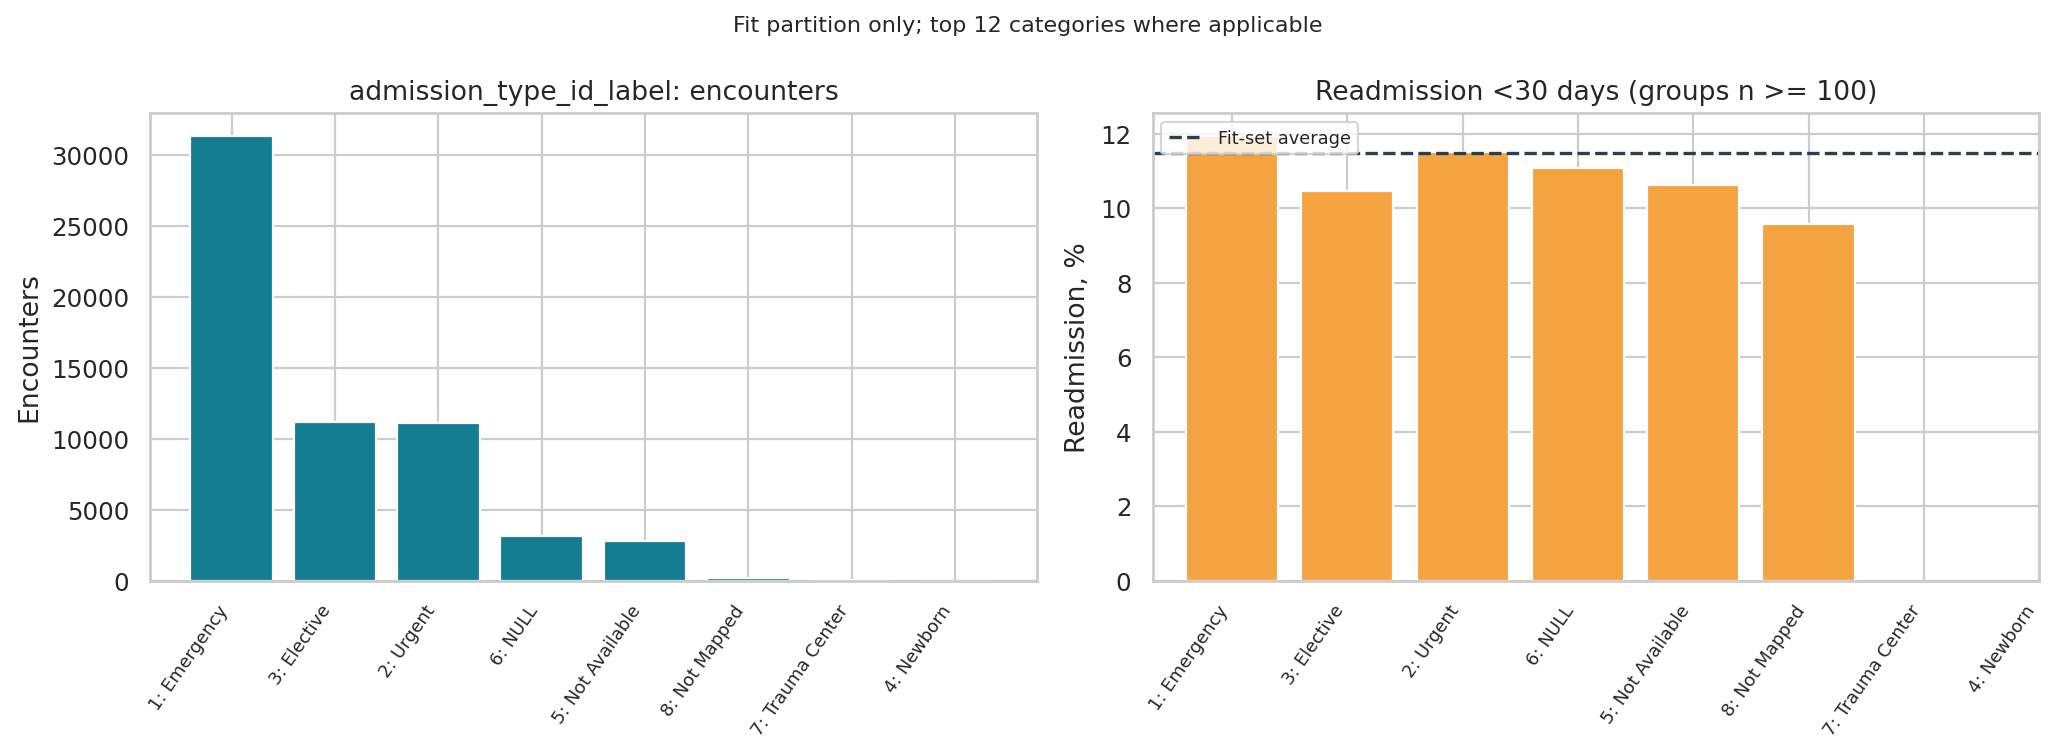

### discharge_disposition_id

,category,encounters,patients,positives,share_pct,readmission_pct,description
0,1,36192,28165,3402,60.588,9.400,Discharged to home
1,3,8541,6645,1254,14.298,14.682,Discharged/transferred to SNF
2,6,7693,6485,1010,12.879,13.129,Discharged/transferred to home with home healt...
3,18,2183,1688,251,3.654,11.498,NaN
4,2,1296,1244,209,2.170,16.127,Discharged/transferred to another short term h...
5,22,1177,1121,330,1.970,28.037,Discharged/transferred to another rehab fac in...
6,5,709,673,148,1.187,20.874,Discharged/transferred to another type of inpa...
7,25,610,549,53,1.021,8.689,Not Mapped
8,4,476,422,64,0.797,13.445,Discharged/transferred to ICF
9,7,352,324,51,0.589,14.489,Left AMA


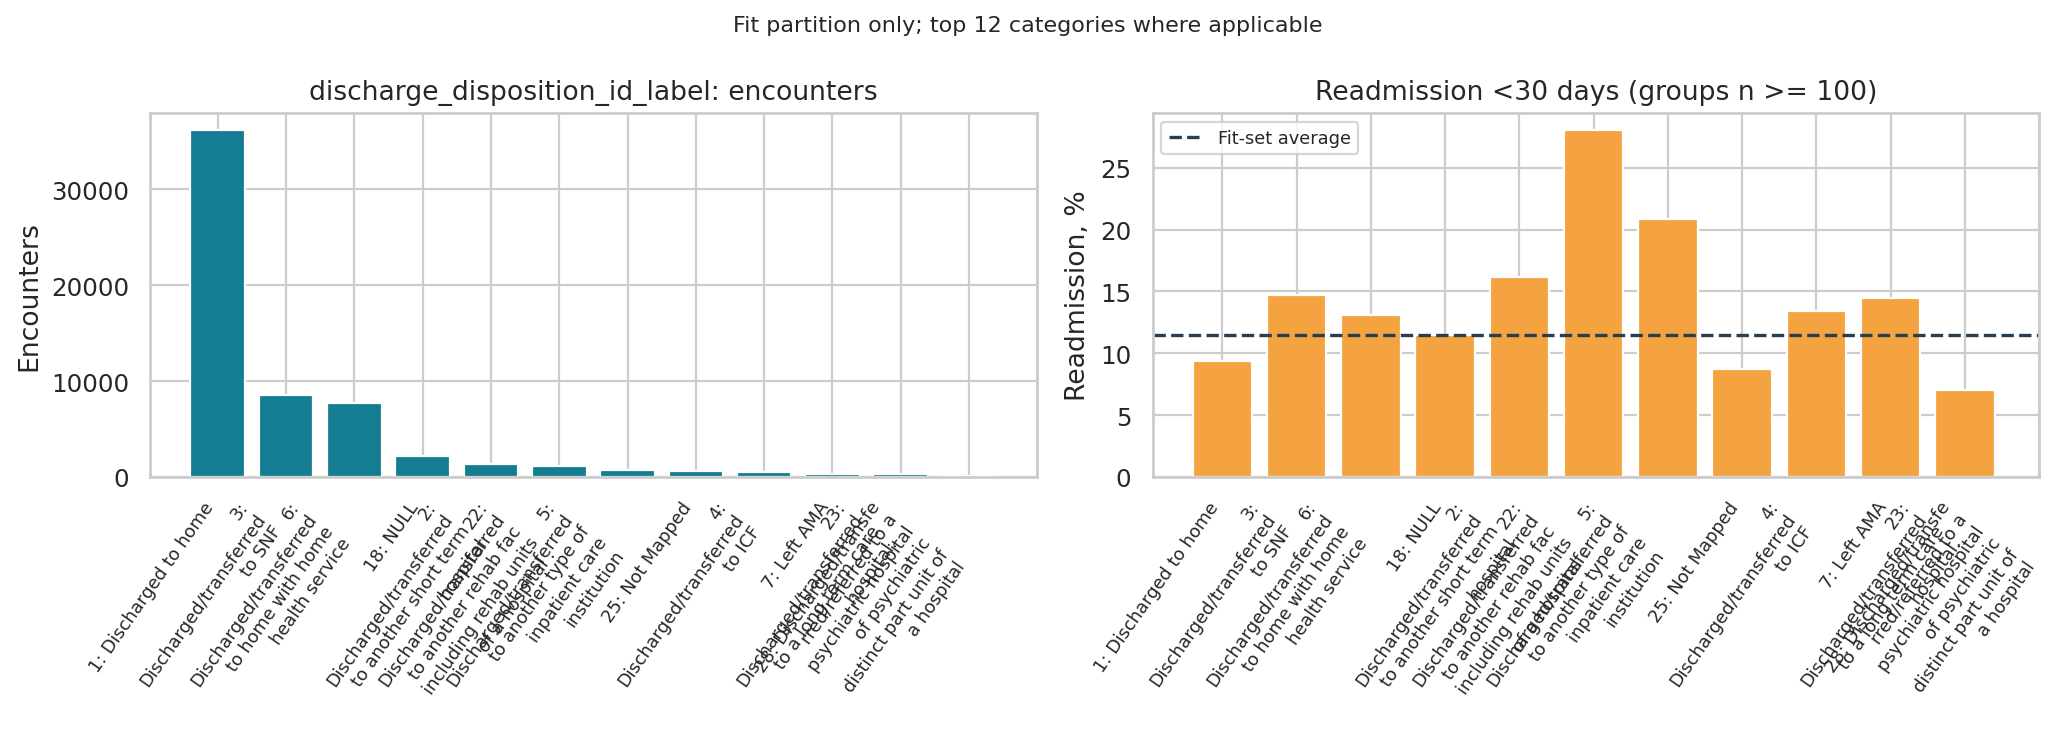

### admission_source_id

,category,encounters,patients,positives,share_pct,readmission_pct,description
0,7,33486,24175,4036,56.058,12.053,Emergency Room
1,1,17545,14821,1887,29.371,10.755,Physician Referral
2,17,3980,2960,426,6.663,10.704,NaN
3,4,1876,1807,186,3.141,9.915,Transfer from a hospital
4,6,1383,1222,139,2.315,10.051,Transfer from another health care facility
5,2,676,641,72,1.132,10.651,Clinic Referral
6,5,491,428,64,0.822,13.035,Transfer from a Skilled Nursing Facility (SNF)
7,3,102,94,16,0.171,15.686,HMO Referral
8,20,96,93,17,0.161,17.708,Not Mapped
9,9,74,72,9,0.124,12.162,Not Available


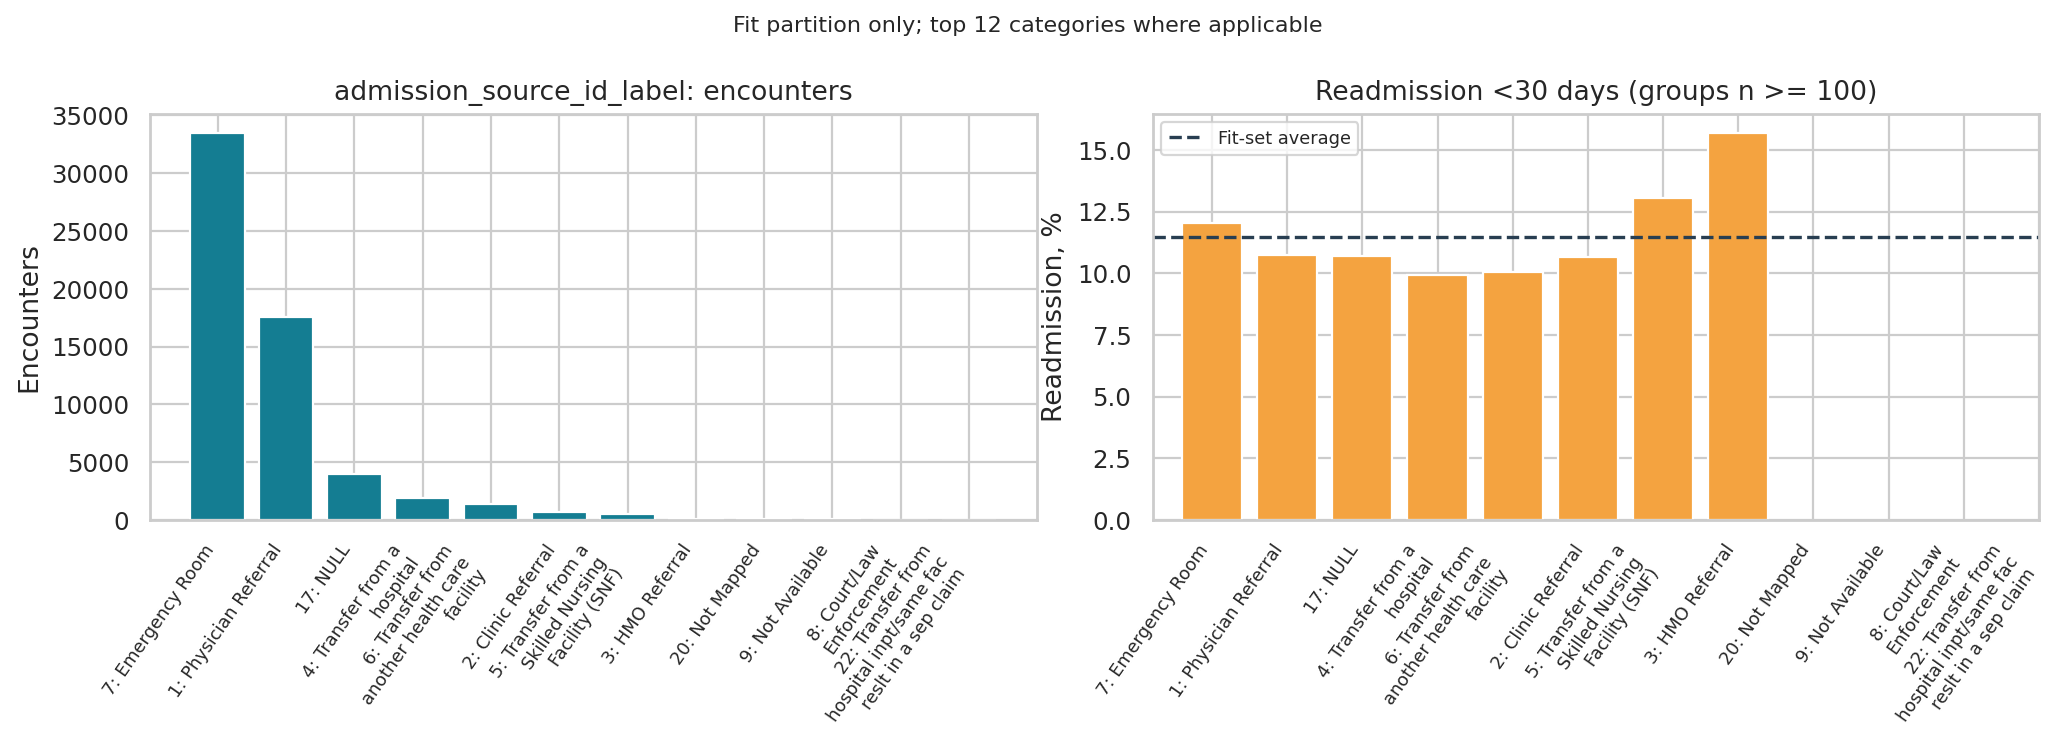

In [10]:
for column in CODE_COLS:
    display(Markdown('### '+column))
    display(table('feature_'+column+'.csv').round(3))
    figure('category_'+column+'_label.png')

## 10 Диагнозы ICD 9
Исходные коды остаются строками. В Pipeline применяется фиксированная укрупнённая схема из статьи Strack et al. 2014. Коды V/E относятся к Other. Группировка сокращает кардинальность, но теряет детализацию.

### diag_1

,diag_1,count
0,428,3959
1,414,3921
2,786,2370
3,410,2097
4,486,2002
5,427,1634
6,491,1340
7,715,1326
8,682,1239
9,780,1198


,category,encounters,patients,positives,share_pct,readmission_pct
0,Circulatory,17878,14666,2108,29.929,11.791
1,Other,10620,9185,1265,17.779,11.911
2,Respiratory,8236,6904,811,13.788,9.847
3,Digestive,5629,4893,619,9.423,10.997
4,Diabetes,5263,4289,693,8.811,13.167
5,Injury,4147,3769,518,6.942,12.491
6,Genitourinary,3048,2819,351,5.103,11.516
7,Musculoskeletal,3035,2871,286,5.081,9.423
8,Neoplasms,1869,1752,200,3.129,10.701
9,Missing,10,10,4,0.017,40.000


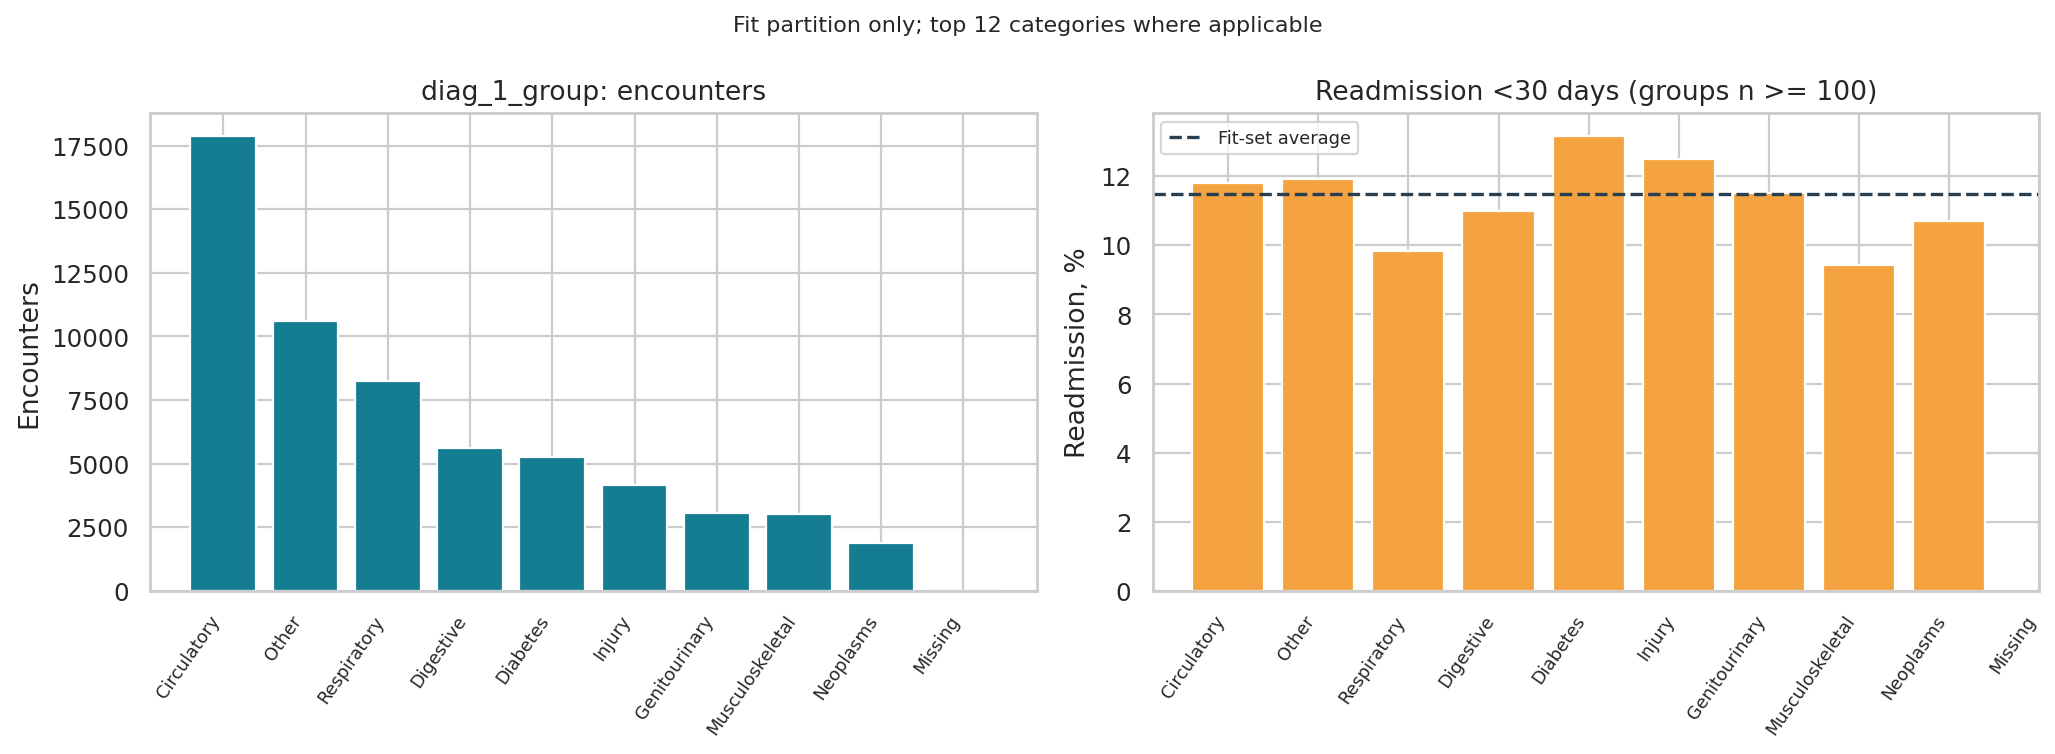

### diag_2

,diag_2,count
0,276,4003
1,428,3858
2,250,3732
3,427,2906
4,401,2189
5,496,2003
6,599,1931
7,403,1688
8,414,1603
9,411,1530


,category,encounters,patients,positives,share_pct,readmission_pct
0,Circulatory,18611,15271,2133,31.156,11.461
1,Other,15794,13284,1824,26.440,11.549
2,Diabetes,7663,7017,836,12.828,10.910
3,Respiratory,6269,5342,723,10.495,11.533
4,Genitourinary,4839,4322,565,8.101,11.676
5,Digestive,2482,2255,280,4.155,11.281
6,Injury,1418,1394,161,2.374,11.354
7,Neoplasms,1380,1160,219,2.310,15.870
8,Musculoskeletal,1070,1028,101,1.791,9.439
9,Missing,209,205,13,0.350,6.220


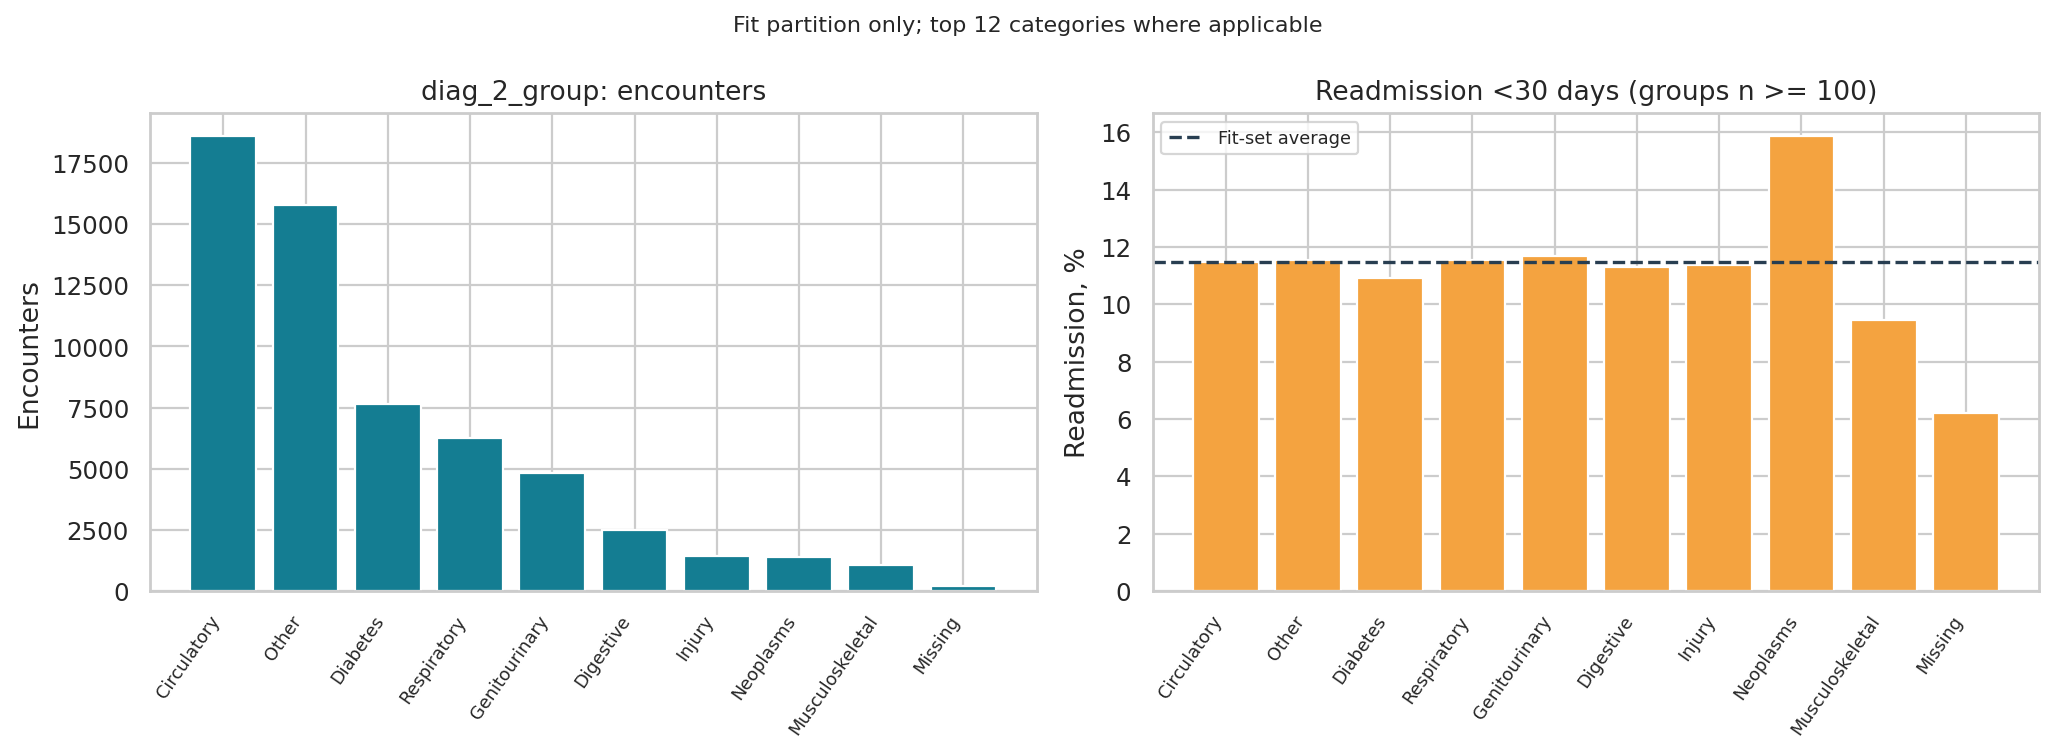

### diag_3

,diag_3,count
0,250,6892
1,401,5081
2,276,2941
3,428,2586
4,427,2257
5,414,2181
6,496,1504
7,403,1391
8,585,1173
9,272,1172


,category,encounters,patients,positives,share_pct,readmission_pct
0,Circulatory,17887,15011,2015,29.944,11.265
1,Other,17106,14593,1928,28.636,11.271
2,Diabetes,10181,9300,1076,17.044,10.569
3,Respiratory,4228,3822,519,7.078,12.275
4,Genitourinary,3864,3486,545,6.469,14.105
5,Digestive,2310,2136,307,3.867,13.290
6,Musculoskeletal,1169,1117,127,1.957,10.864
7,Injury,1139,1115,132,1.907,11.589
8,Neoplasms,971,874,147,1.626,15.139
9,Missing,880,836,59,1.473,6.705


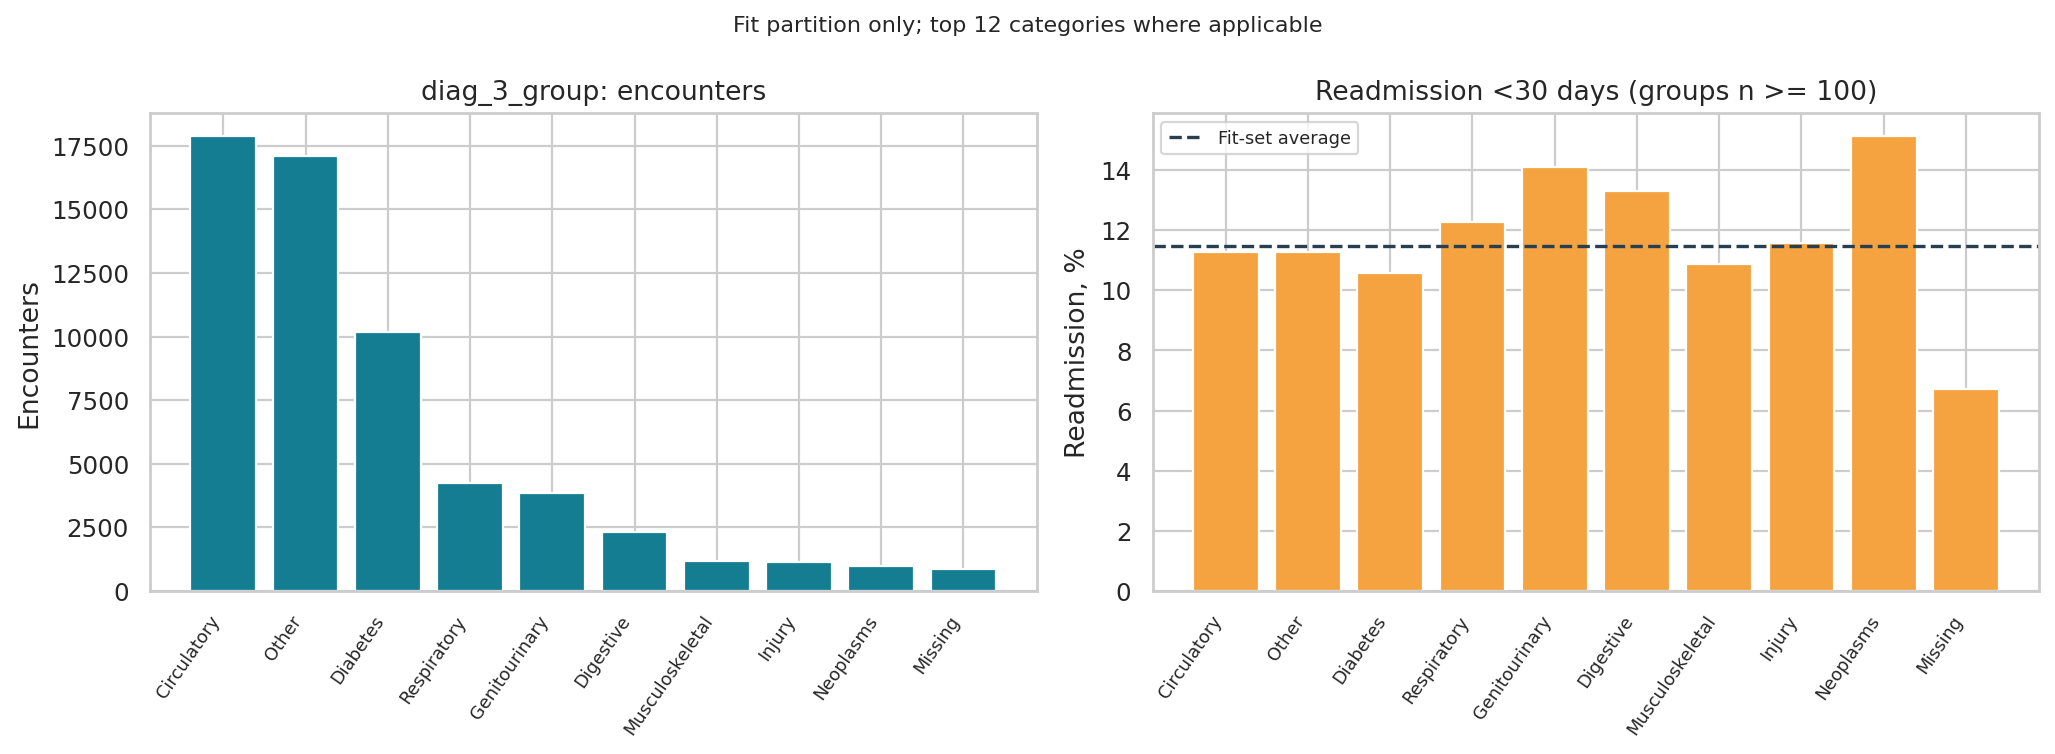

In [11]:
from src.features import icd9_group
for column in DIAG_COLS:
    display(Markdown('### '+column))
    display(table('raw_'+column+'_counts.csv').head(15))
    display(table('feature_'+column+'_group.csv').round(3))
    figure('category_'+column+'_group.png')

## 11 Анализы и общие признаки терапии
Лабораторные результаты представлены категориями, не точными концентрациями. Различие частот <30 между вариантами лечения не доказывает эффект препарата: тяжесть состояния влияет и на назначение, и на исход.

,category,encounters,patients,positives,share_pct,readmission_pct
0,NaN,49619,35698,5848,83.065,11.786
1,>8,4916,4433,486,8.230,9.886
2,Norm,2944,2781,300,4.928,10.190
3,>7,2256,2168,221,3.777,9.796


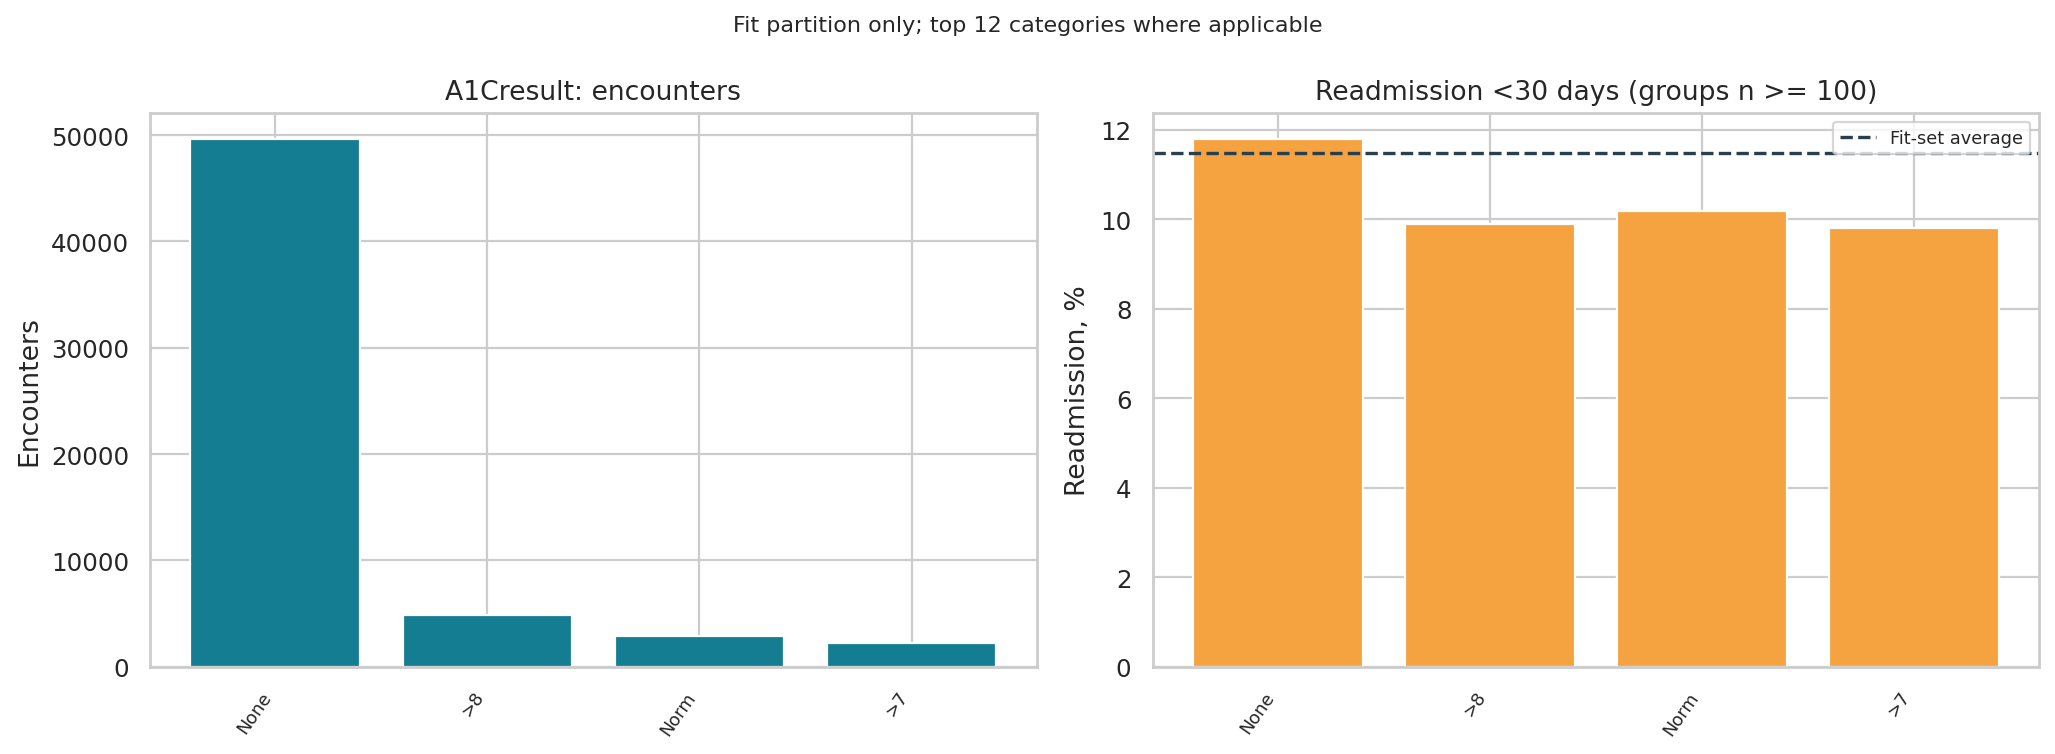

,category,encounters,patients,positives,share_pct,readmission_pct
0,NaN,56712,40071,6471,94.939,11.410
1,Norm,1524,1176,171,2.551,11.220
2,>200,827,704,110,1.384,13.301
3,>300,672,525,103,1.125,15.327


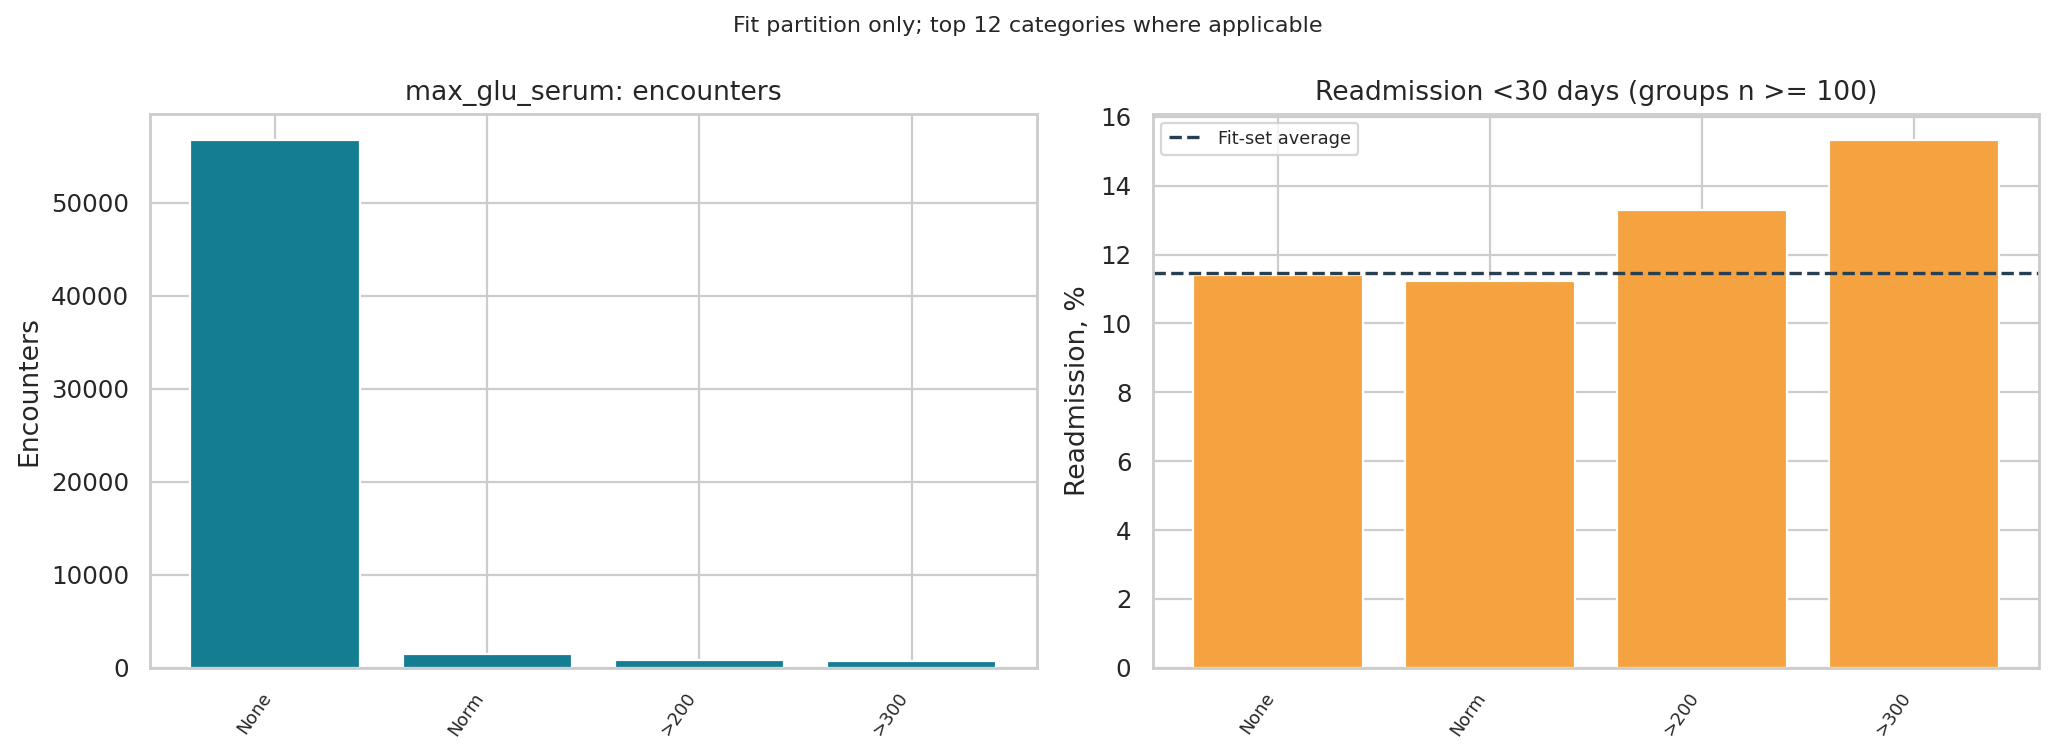

,category,encounters,patients,positives,share_pct,readmission_pct
0,No,32027,25065,3521,53.615,10.994
1,Ch,27708,20730,3334,46.385,12.033


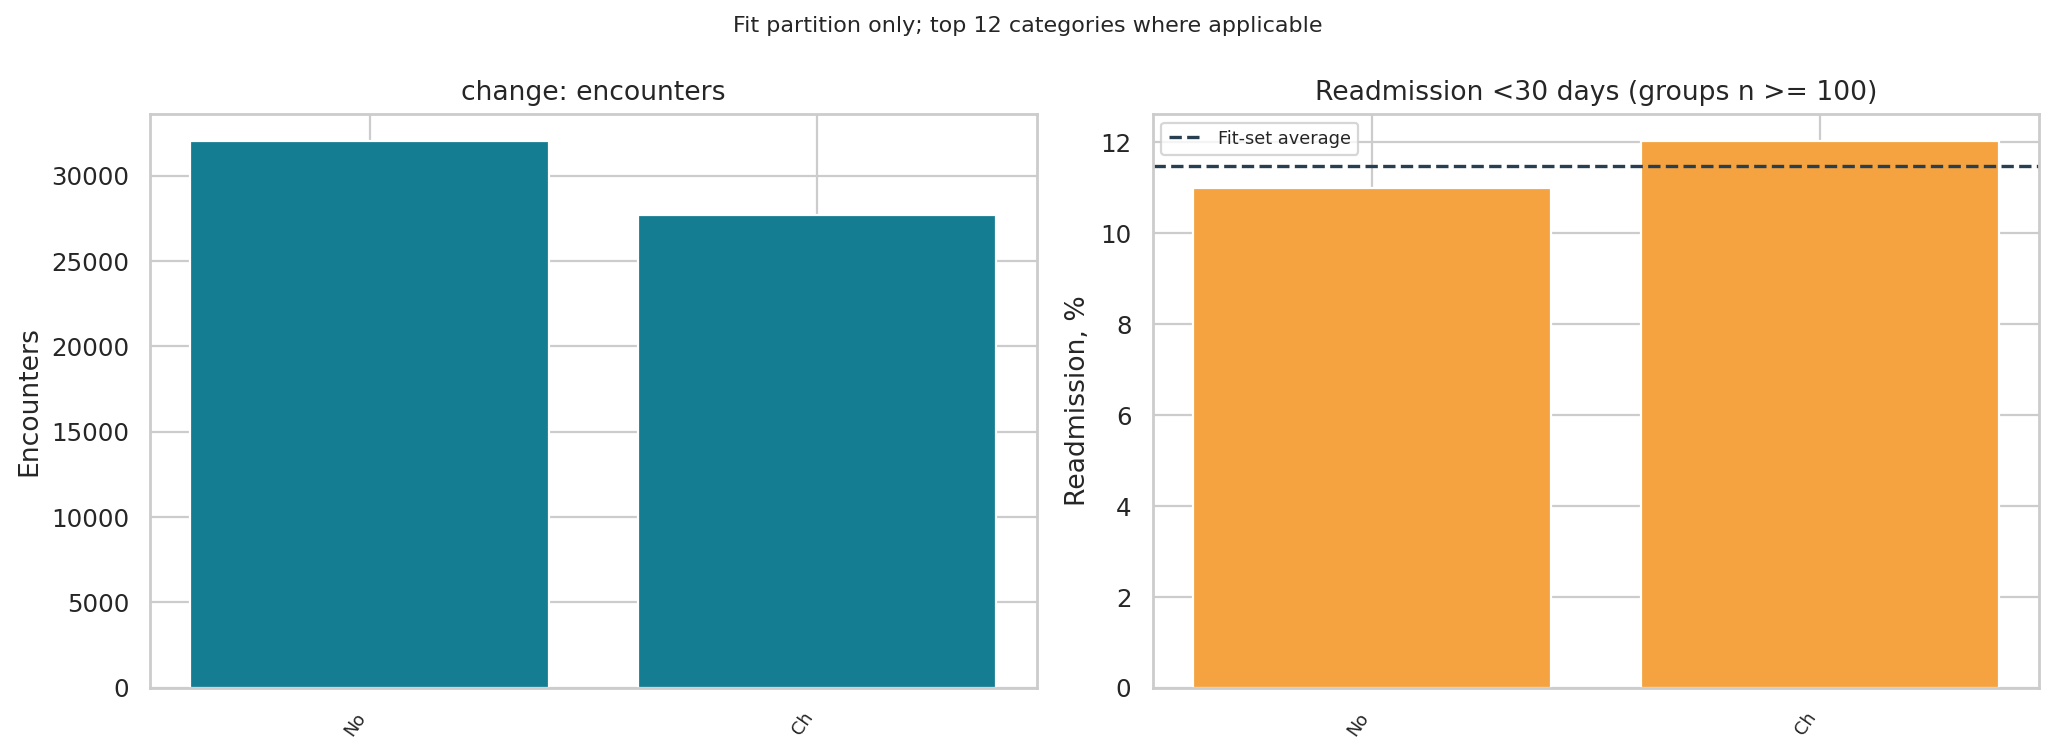

,category,encounters,patients,positives,share_pct,readmission_pct
0,Yes,46196,33074,5513,77.335,11.934
1,No,13539,11361,1342,22.665,9.912


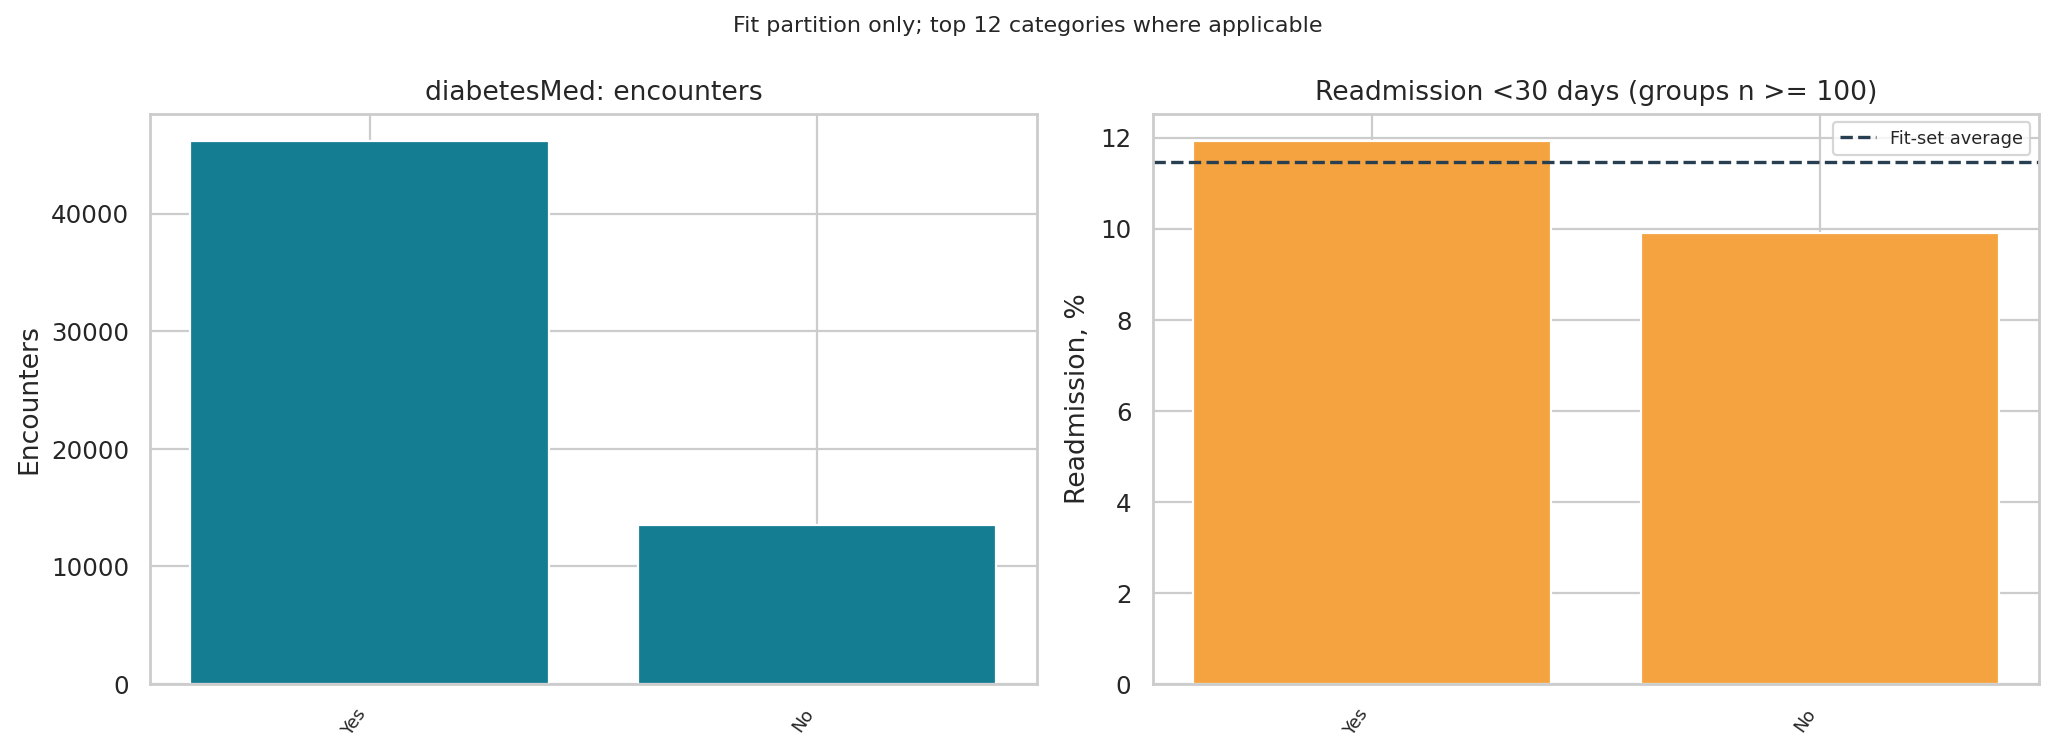

In [12]:
for column in ['A1Cresult','max_glu_serum','change','diabetesMed']:
    display(table('feature_'+column+'.csv').round(3))
    figure('category_'+column+'.png')

## 12 Все 23 лекарственных столбца
No — не назначался; Steady — дозировка без изменения; Up/Down — увеличение/уменьшение. Проверяем константы и редкие назначения. Столбцы examide и citoglipton постоянны в данном источнике.

,Unnamed: 0,No,Steady,Up,Down,Missing
0,metformin,47656.0,11104.0,637.0,338.0,0
1,repaglinide,58843.0,809.0,61.0,22.0,0
2,nateglinide,59336.0,384.0,9.0,6.0,0
3,chlorpropamide,59696.0,36.0,2.0,1.0,0
4,glimepiride,56597.0,2841.0,178.0,119.0,0
5,acetohexamide,59734.0,1.0,0.0,0.0,0
6,glipizide,52194.0,6761.0,473.0,307.0,0
7,glyburide,53402.0,5532.0,470.0,331.0,0
8,tolbutamide,59724.0,11.0,0.0,0.0,0
9,pioglitazone,55300.0,4215.0,149.0,71.0,0


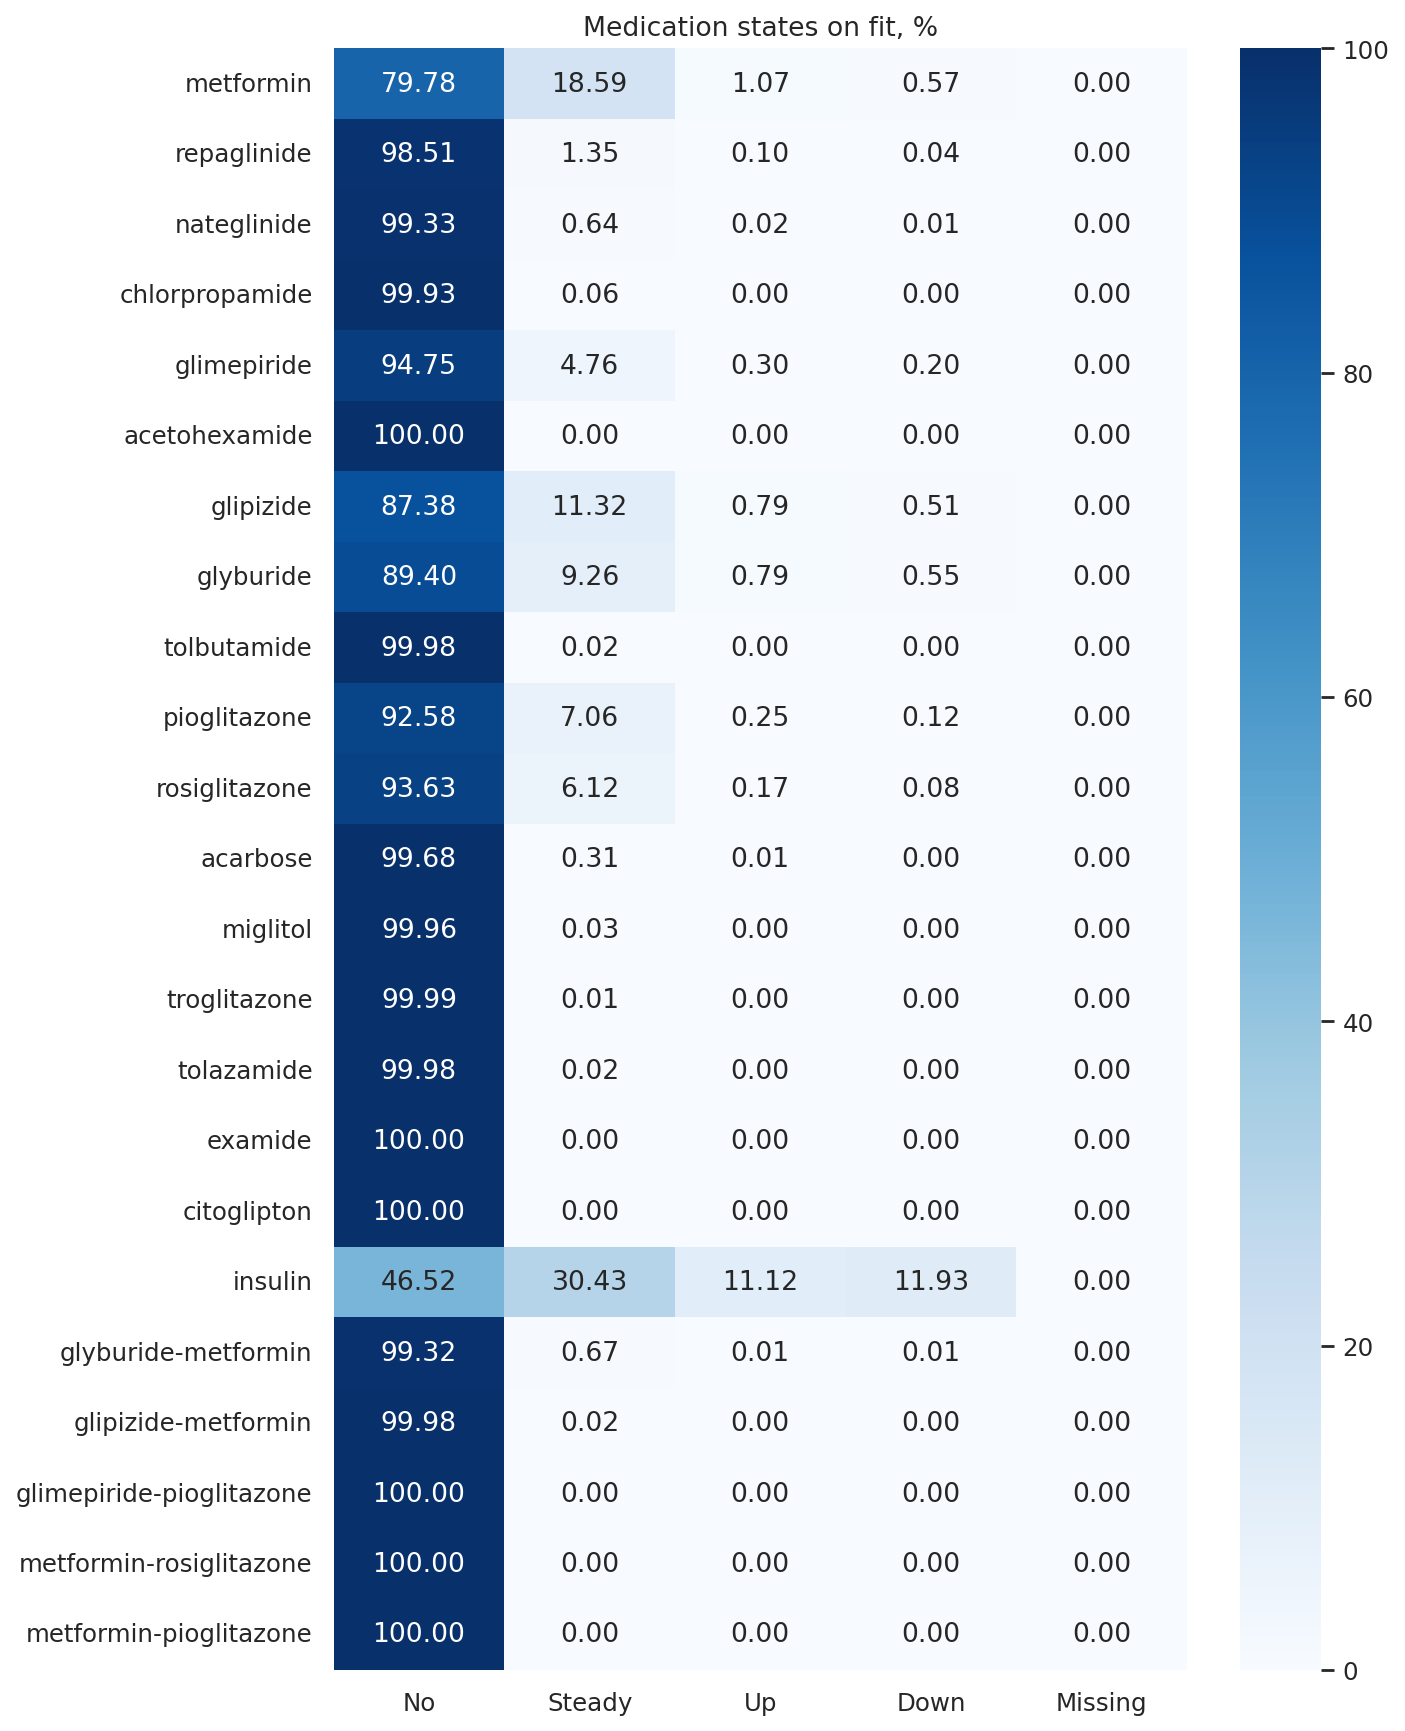

,drug,status,encounters,patients,positives,share_pct,readmission_pct
0,metformin,No,47656,34036,5656,79.779,11.868
1,metformin,Steady,11104,9194,1106,18.589,9.960
2,metformin,Up,637,619,54,1.066,8.477
3,metformin,Down,338,326,39,0.566,11.538
4,repaglinide,No,58843,41537,6738,98.507,11.451
5,repaglinide,Steady,809,626,109,1.354,13.473
6,repaglinide,Up,61,59,8,0.102,13.115
7,repaglinide,Down,22,22,0,0.037,0.000
8,nateglinide,No,59336,41760,6808,99.332,11.474
9,nateglinide,Steady,384,310,47,0.643,12.240


In [13]:
display(table('medication_counts.csv'))
figure('08_medication_states.png',850)
display(table('medication_target_rates.csv').round(3))

## 13 Корреляции и предыдущие обращения
Spearman исследует монотонные связи, но не описывает всю нелинейную предсказательную информацию. Большая группа не обязательно имеет больший риск: сравниваем доли внутри групп.

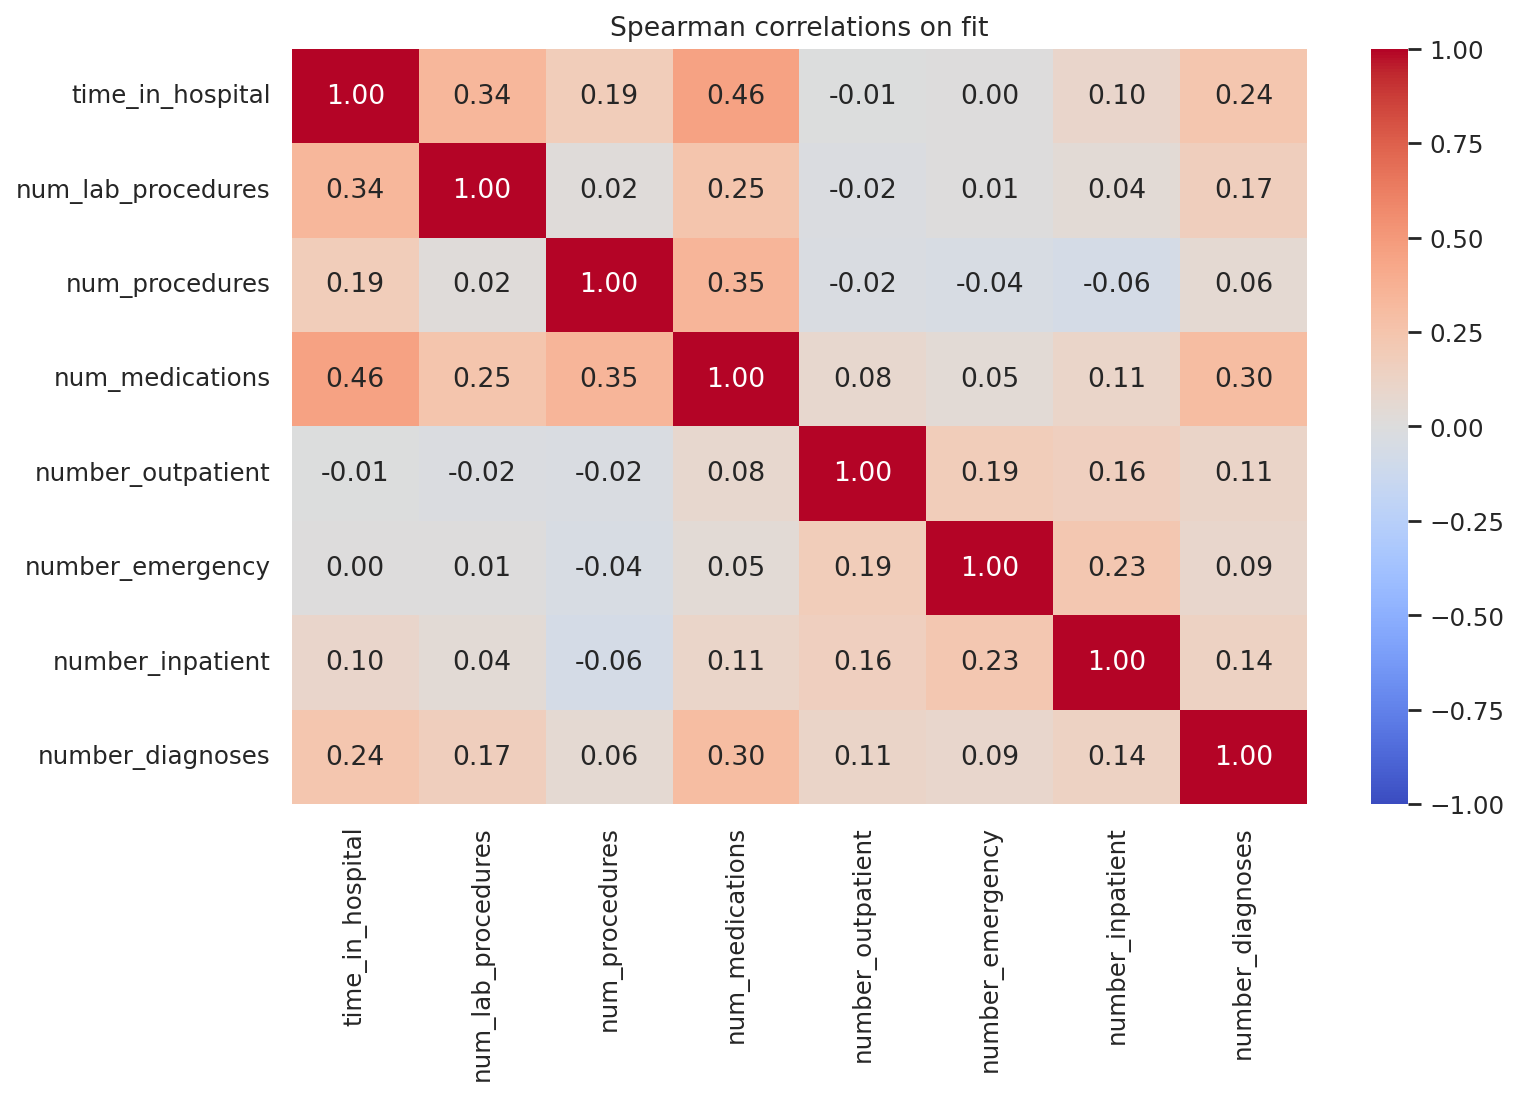

,Unnamed: 0,readmitted_30d
0,num_procedures,-0.0079
1,num_lab_procedures,0.0235
2,number_outpatient,0.0387
3,num_medications,0.0490
4,number_diagnoses,0.0532
5,time_in_hospital,0.0557
6,number_emergency,0.0670
7,number_inpatient,0.1428


,category,encounters,patients,positives,share_pct,readmission_pct
0,0,49932,36891,5452,83.589,10.919
1,1,5048,3790,742,8.451,14.699
2,3+,2679,1889,361,4.485,13.475
3,2,2076,1659,300,3.475,14.451


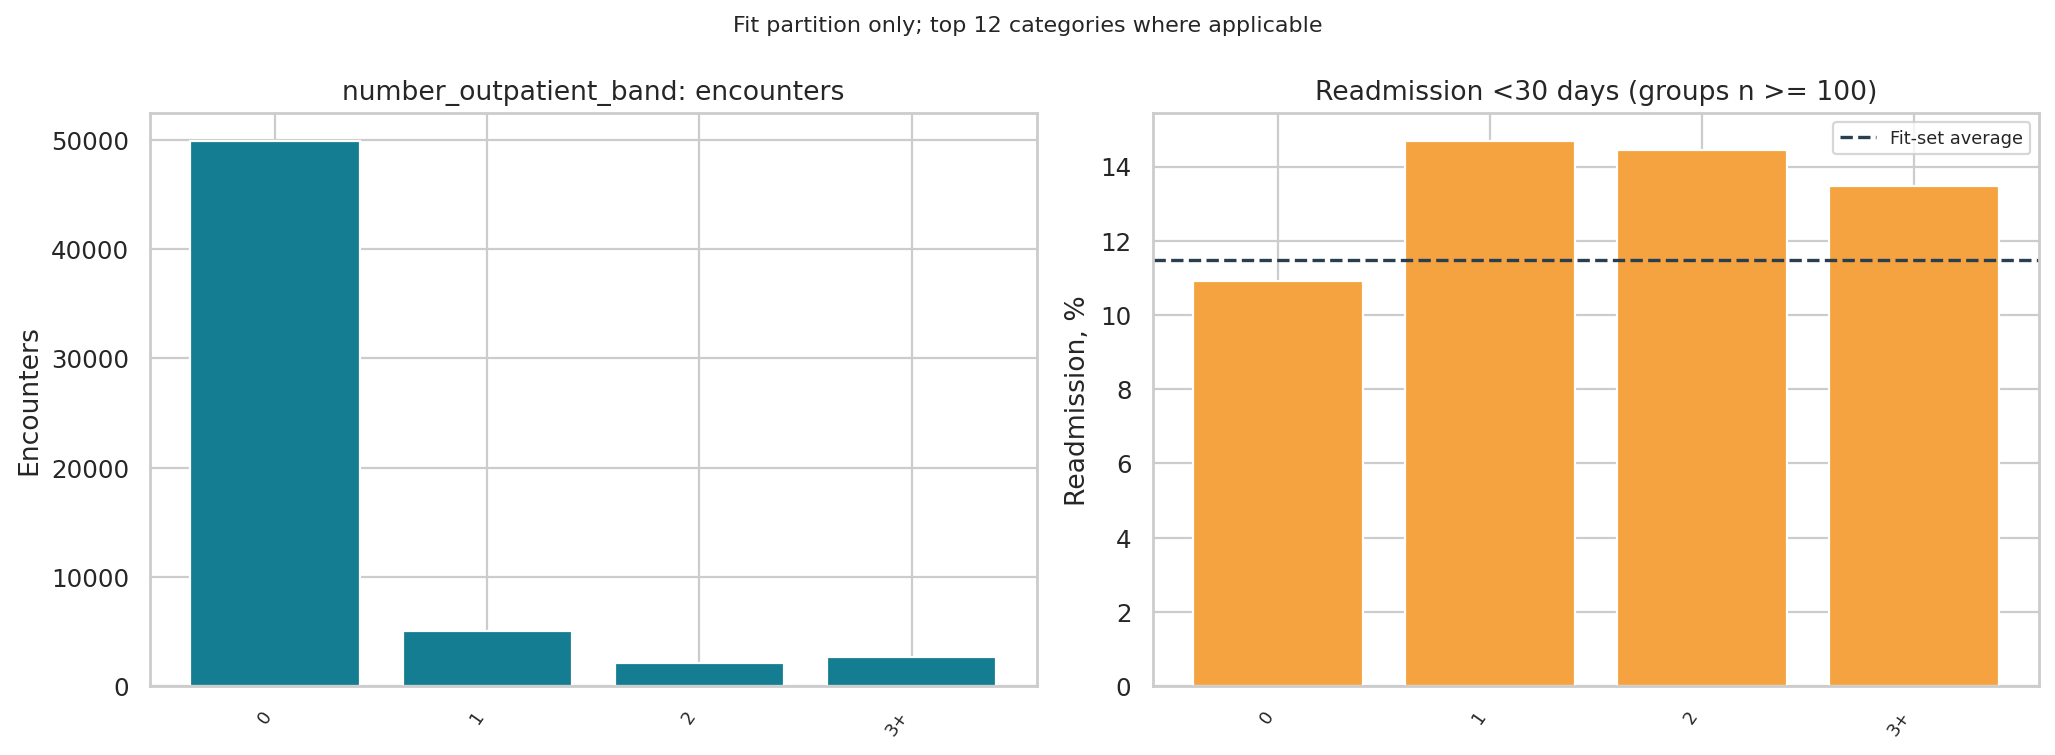

,category,encounters,patients,positives,share_pct,readmission_pct
0,0,52959,39240,5684,88.657,10.733
1,1,4560,3327,700,7.634,15.351
2,2,1216,872,223,2.036,18.339
3,3+,1000,493,248,1.674,24.800


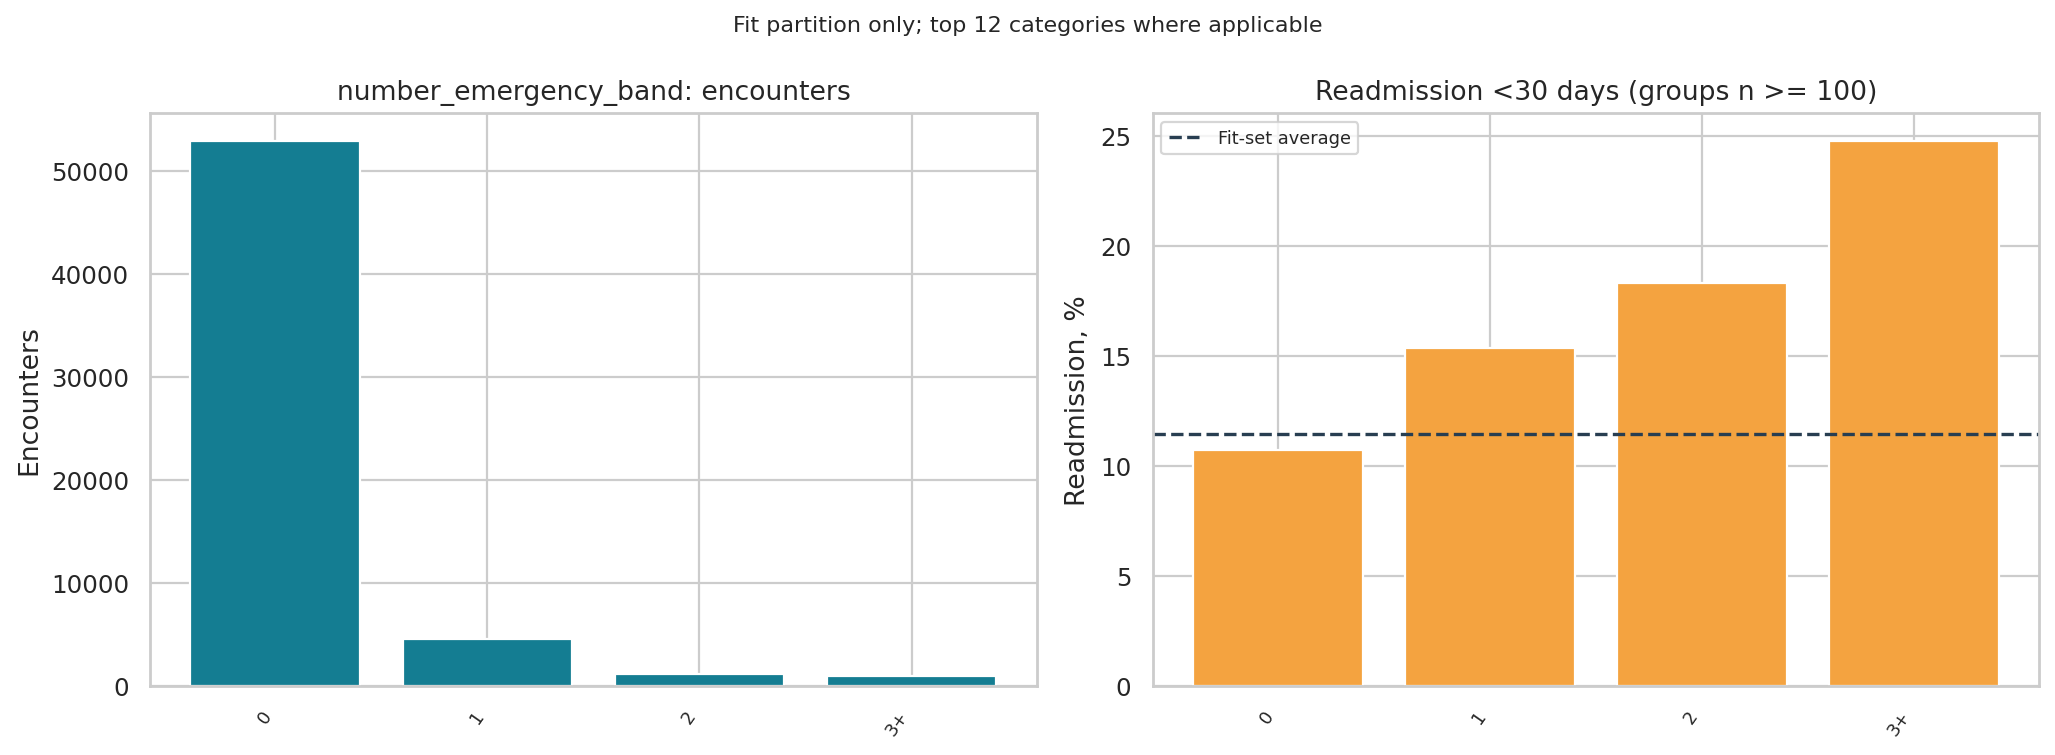

,category,encounters,patients,positives,share_pct,readmission_pct
0,0,39741,37483,3425,66.529,8.618
1,1,11438,10472,1540,19.148,13.464
2,2,4407,3935,807,7.378,18.312
3,3+,4149,2147,1083,6.946,26.103


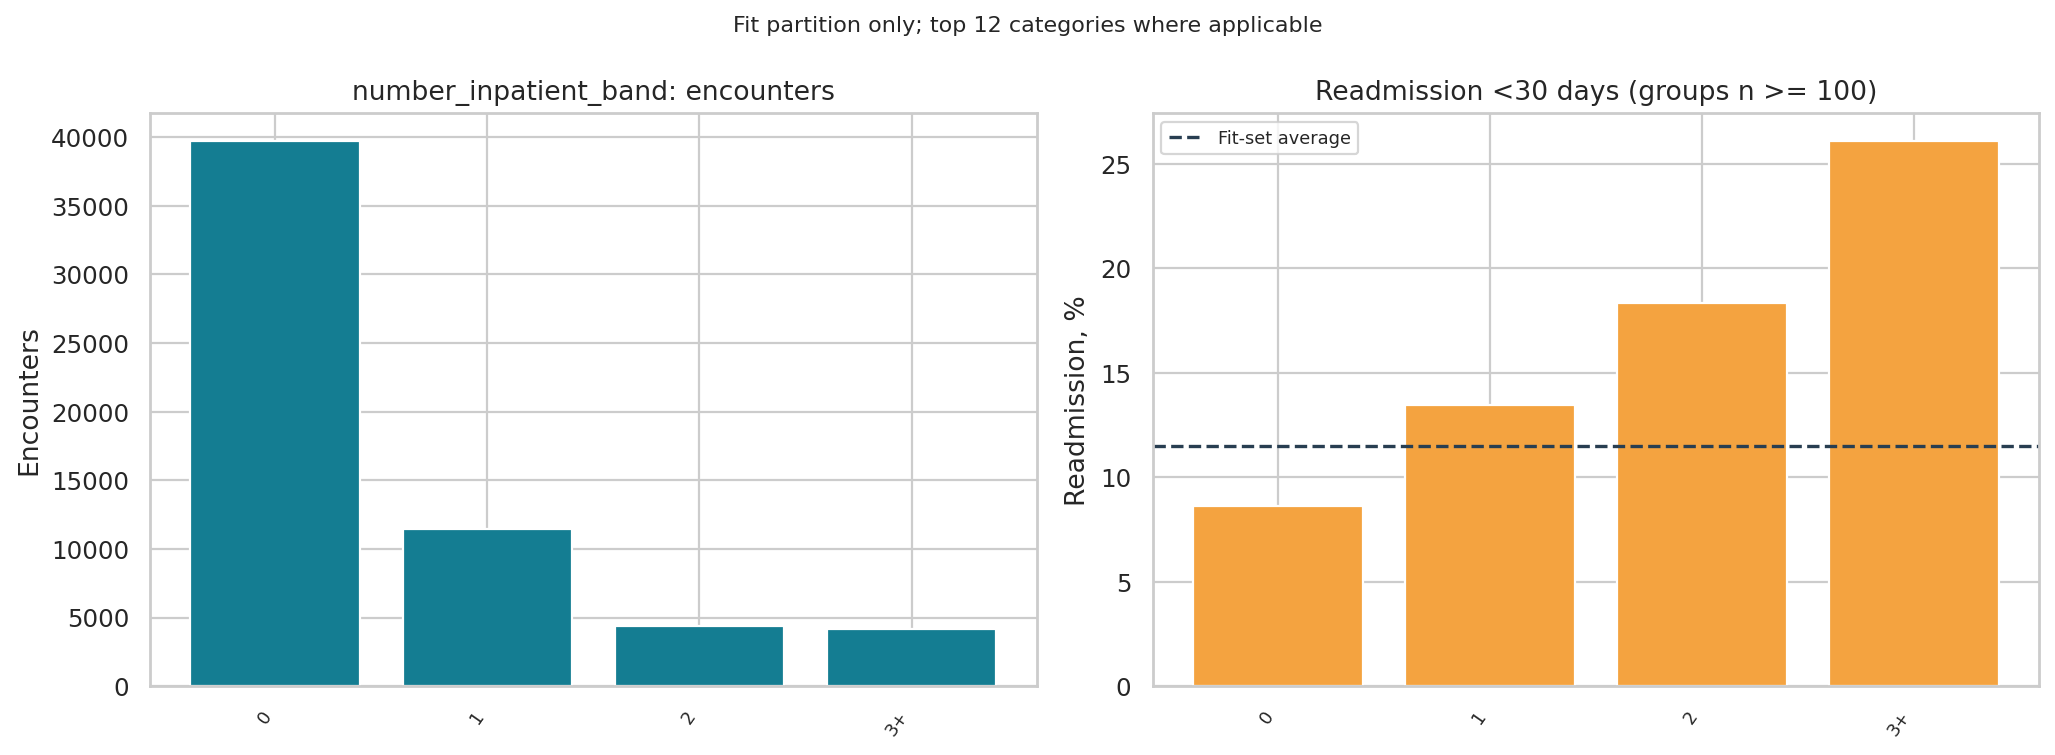

In [14]:
figure('07_spearman.png')
display(table('target_spearman.csv').round(4))
for column in ['number_outpatient','number_emergency','number_inpatient']:
    display(table('feature_'+column+'_band.csv').round(3))
    figure('category_'+column+'_band.png')

## 14 Память и хранение
Размер CSV на диске и память DataFrame различаются. Оптимизация типов показана отдельно, не подменяет обучаемые преобразования Pipeline. Исходные данные сохранены также в Parquet.

,value
before_MiB,49.479876
after_MiB,5.851109
reduction_pct,88.174771


CSV MiB: 18.271811485290527


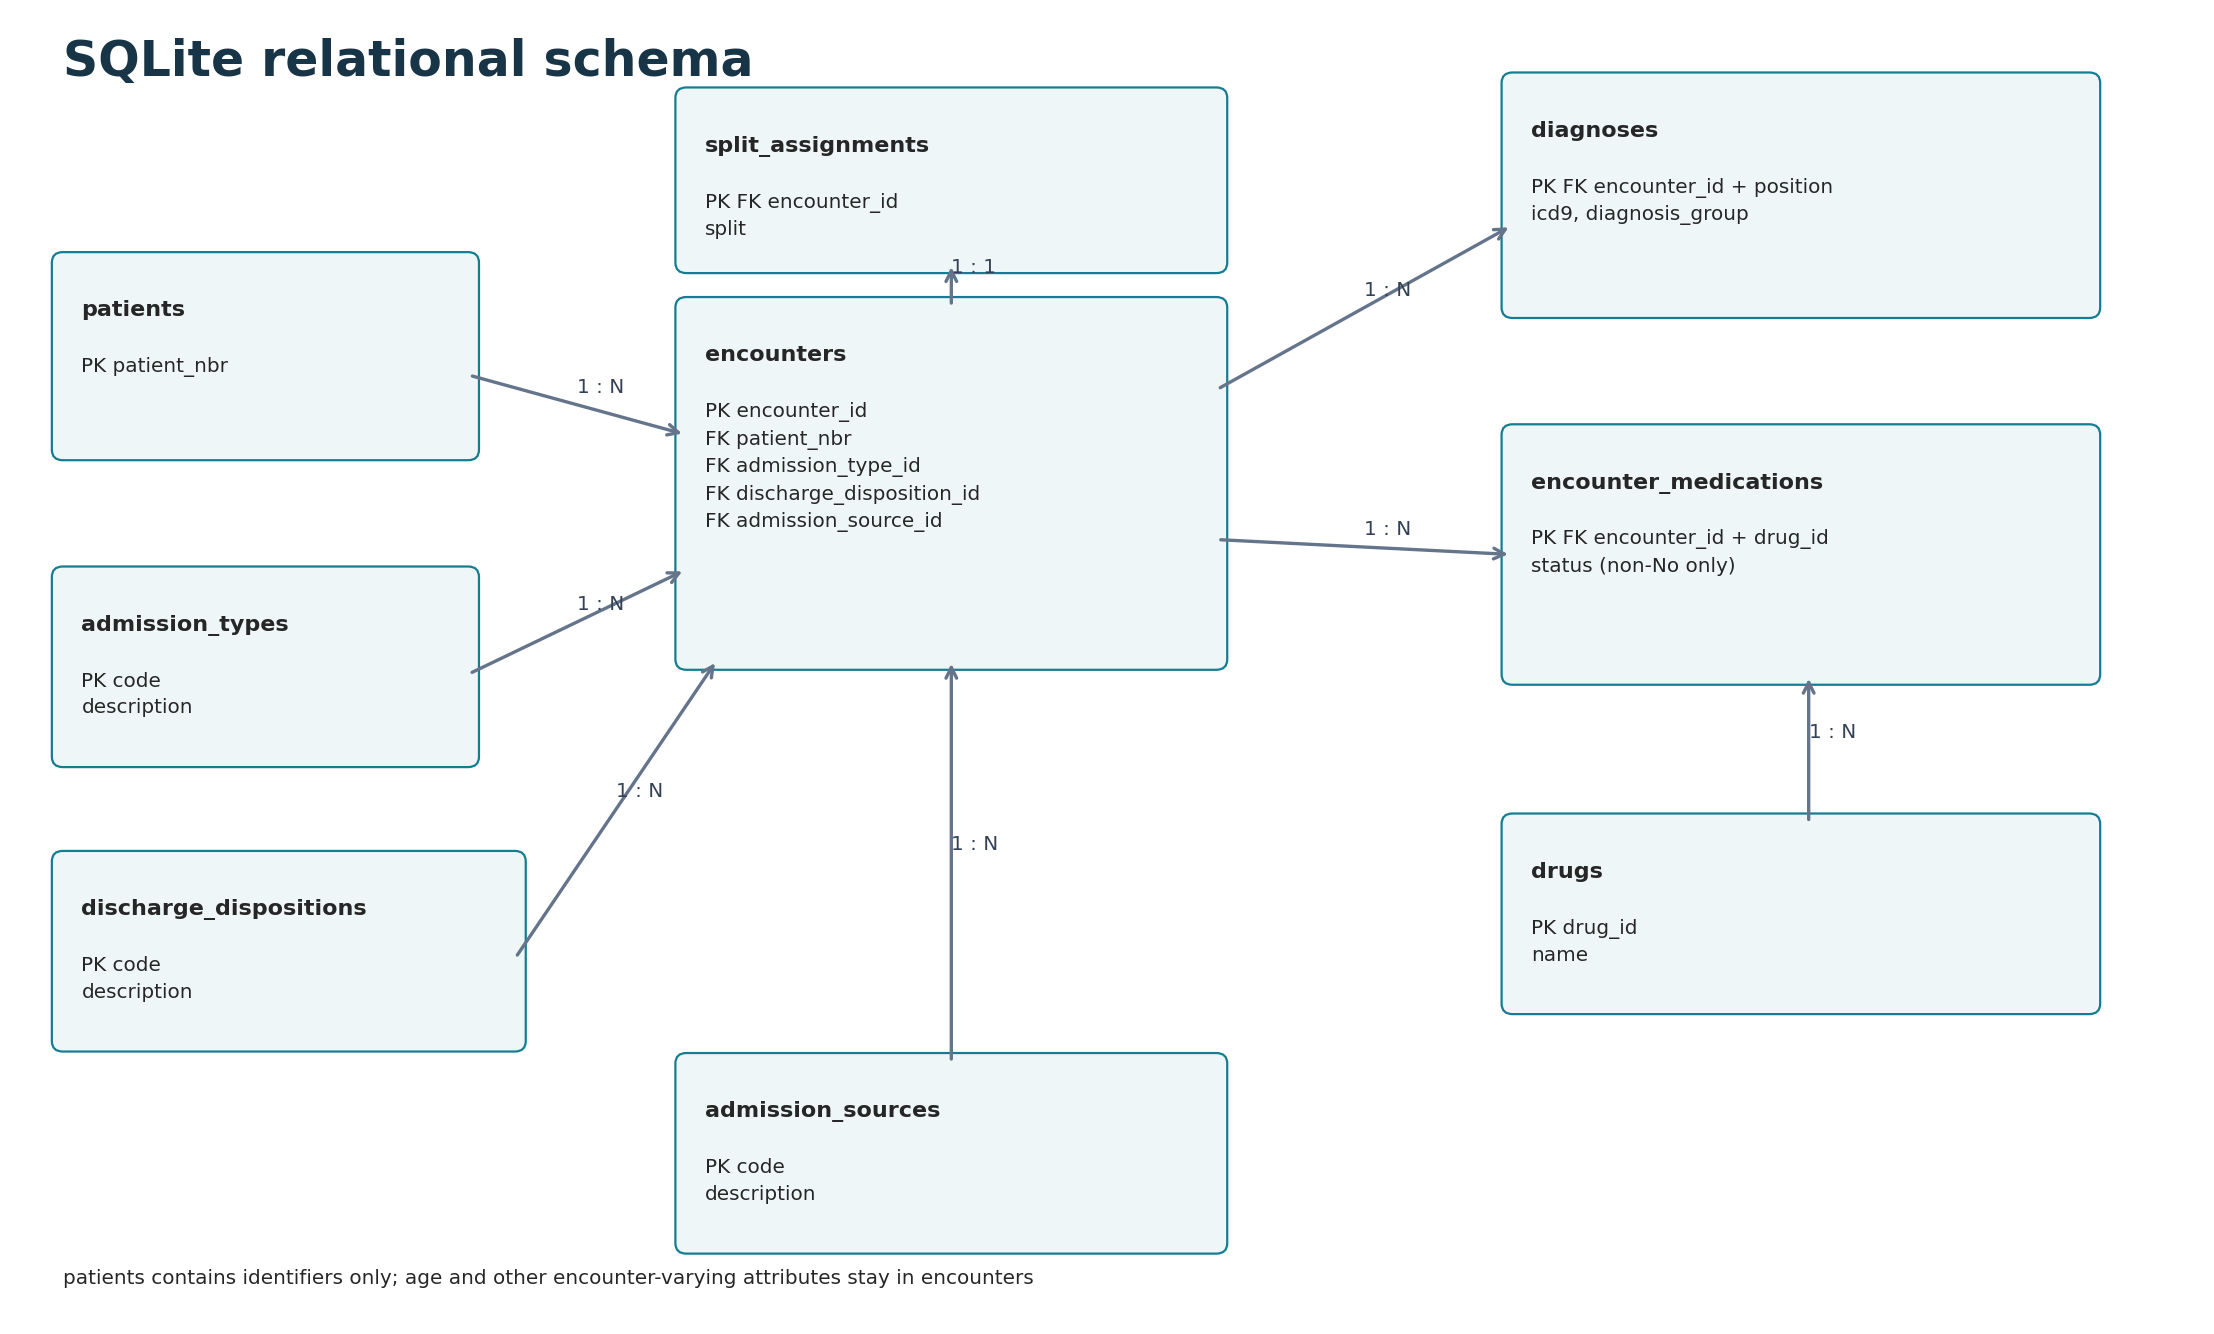

In [15]:
summary=json.loads((REPORTS/'data_summary.json').read_text(encoding='utf-8'))
display(pd.Series(summary['memory']).to_frame('value'))
print('CSV MiB:',source_info['csv_bytes']/1024**2)
figure('er_diagram.png')

## 15 Выводы по каждому исходному столбцу

In [16]:
display(Markdown((REPORTS/'EDA_detailed_conclusions.md').read_text(encoding='utf-8')))

# Подробные выводы EDA по всем исходным столбцам

Единица наблюдения — госпитализация. Общий аудит относится к исходным данным; связи с целью рассчитаны только на fit.
Частоты не являются доказательством причинности. Исходные файлы и исходные записи не исправлялись автоматически.

## encounter_id
- Тип: int64; уникальных значений: 101766.
- Пропуски: 0 (0.00%).
- Доля наиболее частого значения: 0.00%.
**Решение:** Технический идентификатор, исключён из входов модели.

## patient_nbr
- Тип: int64; уникальных значений: 71518.
- Пропуски: 0 (0.00%).
- Доля наиболее частого значения: 0.04%.
**Решение:** Технический идентификатор, исключён из входов модели. Используется для всех разбиений и групповой кросс-валидации; повторы не удаляются.

## race
- Тип: string; уникальных значений: 5.
- Пропуски: 2,273 (2.23%).
- Доля наиболее частого значения: 74.78%.
- На fit наиболее многочисленная категория Caucasian: 44,534 госпитализаций; доля <30 внутри неё 11.55%.
- Среди категорий с n ≥ 100 наблюдаемые доли <30 на fit: от 8.78% (Missing) до 11.66% (AfricanAmerican). Это описательное сравнение без утверждения значимости или причинности.
**Решение:** Категориальный признак. Импутация отдельной категорией и One-Hot Encoding с объединением редких уровней обучаются только на тренировочных фолдах.

## gender
- Тип: string; уникальных значений: 3.
- Пропуски: 0 (0.00%).
- Доля наиболее частого значения: 53.76%.
- На fit наиболее многочисленная категория Female: 32,227 госпитализаций; доля <30 внутри неё 11.56%.
- Среди категорий с n ≥ 100 наблюдаемые доли <30 на fit: от 11.38% (Male) до 11.56% (Female). Это описательное сравнение без утверждения значимости или причинности.
**Решение:** Категориальный признак. Импутация отдельной категорией и One-Hot Encoding с объединением редких уровней обучаются только на тренировочных фолдах.

## age
- Тип: string; уникальных значений: 10.
- Пропуски: 0 (0.00%).
- Доля наиболее частого значения: 25.62%.
- На fit наиболее многочисленная категория [70-80): 15,258 госпитализаций; доля <30 внутри неё 12.21%.
- Среди категорий с n ≥ 100 наблюдаемые доли <30 на fit: от 0.00% ([0-10)) до 13.72% ([20-30)). Это описательное сравнение без утверждения значимости или причинности.
**Решение:** Категориальный признак. Импутация отдельной категорией и One-Hot Encoding с объединением редких уровней обучаются только на тренировочных фолдах.

## weight
- Тип: string; уникальных значений: 9.
- Пропуски: 98,569 (96.86%).
- Доля наиболее частого значения: 96.86%.
- На fit наиболее многочисленная категория Missing: 57,864 госпитализаций; доля <30 внутри неё 11.48%.
- Среди категорий с n ≥ 100 наблюдаемые доли <30 на fit: от 11.05% ([100-125)) до 12.18% ([50-75)). Это описательное сравнение без утверждения значимости или причинности.
**Решение:** 96,86% пропусков. Исходные интервалы исключены из первой модели, используется индикатор наличия записи. Строки не удаляются.

## admission_type_id
- Тип: string; уникальных значений: 8.
- Пропуски: 0 (0.00%).
- Доля наиболее частого значения: 53.05%.
- На fit наиболее многочисленная категория 1: 31,354 госпитализаций; доля <30 внутри неё 11.96%.
- Среди категорий с n ≥ 100 наблюдаемые доли <30 на fit: от 9.57% (8) до 11.96% (1). Это описательное сравнение без утверждения значимости или причинности.
**Решение:** Номинальный код со справочником IDS_mapping.csv. Не интерпретировать как число. Неизвестные коды нормализуются в Pipeline.

## discharge_disposition_id
- Тип: string; уникальных значений: 26.
- Пропуски: 0 (0.00%).
- Доля наиболее частого значения: 59.19%.
- На fit наиболее многочисленная категория 1: 36,192 госпитализаций; доля <30 внутри неё 9.40%.
- Среди категорий с n ≥ 100 наблюдаемые доли <30 на fit: от 7.00% (23) до 28.04% (22). Это описательное сравнение без утверждения значимости или причинности.
**Решение:** Номинальный код со справочником IDS_mapping.csv. Не интерпретировать как число. Неизвестные коды нормализуются в Pipeline.

## admission_source_id
- Тип: string; уникальных значений: 17.
- Пропуски: 0 (0.00%).
- Доля наиболее частого значения: 56.50%.
- На fit наиболее многочисленная категория 7: 33,486 госпитализаций; доля <30 внутри неё 12.05%.
- Среди категорий с n ≥ 100 наблюдаемые доли <30 на fit: от 9.91% (4) до 15.69% (3). Это описательное сравнение без утверждения значимости или причинности.
**Решение:** Номинальный код со справочником IDS_mapping.csv. Не интерпретировать как число. Неизвестные коды нормализуются в Pipeline.

## time_in_hospital
- Тип: int64; уникальных значений: 14.
- Пропуски: 0 (0.00%).
- Доля наиболее частого значения: 17.45%.
- На fit: среднее 4.37, медиана 4.00, P99 13.00, максимум 14.
- Нулей 0.00%; IQR 4.00; за диагностическими границами IQR 2.09%.
**Решение:** Количественный признак. Проверены квартили, нули, хвосты, IQR и связь с целью на fit. Экстремальные значения не удаляются автоматически. Медианная импутация и масштабирование обучаются внутри CV.

## payer_code
- Тип: string; уникальных значений: 17.
- Пропуски: 40,256 (39.56%).
- Доля наиболее частого значения: 39.56%.
- На fit наиболее многочисленная категория Missing: 23,576 госпитализаций; доля <30 внутри неё 11.74%.
- Среди категорий с n ≥ 100 наблюдаемые доли <30 на fit: от 7.26% (PO) до 13.93% (DM). Это описательное сравнение без утверждения значимости или причинности.
**Решение:** Категориальный признак. Импутация отдельной категорией и One-Hot Encoding с объединением редких уровней обучаются только на тренировочных фолдах.

## medical_specialty
- Тип: string; уникальных значений: 72.
- Пропуски: 49,949 (49.08%).
- Доля наиболее частого значения: 49.08%.
- На fit наиболее многочисленная категория Missing: 29,240 госпитализаций; доля <30 внутри неё 11.98%.
- Среди категорий с n ≥ 100 наблюдаемые доли <30 на fit: от 4.02% (ObstetricsandGynecology) до 22.22% (Hematology/Oncology). Это описательное сравнение без утверждения значимости или причинности.
**Решение:** Категориальный признак. Импутация отдельной категорией и One-Hot Encoding с объединением редких уровней обучаются только на тренировочных фолдах.

## num_lab_procedures
- Тип: int64; уникальных значений: 118.
- Пропуски: 0 (0.00%).
- Доля наиболее частого значения: 3.15%.
- На fit: среднее 42.91, медиана 44.00, P99 84.00, максимум 132.
- Нулей 0.00%; IQR 26.00; за диагностическими границами IQR 0.11%.
**Решение:** Количественный признак. Проверены квартили, нули, хвосты, IQR и связь с целью на fit. Экстремальные значения не удаляются автоматически. Медианная импутация и масштабирование обучаются внутри CV.

## num_procedures
- Тип: int64; уникальных значений: 7.
- Пропуски: 0 (0.00%).
- Доля наиболее частого значения: 45.84%.
- На fit: среднее 1.33, медиана 1.00, P99 6.00, максимум 6.
- Нулей 46.13%; IQR 2.00; за диагностическими границами IQR 4.74%.
**Решение:** Количественный признак. Проверены квартили, нули, хвосты, IQR и связь с целью на fit. Экстремальные значения не удаляются автоматически. Медианная импутация и масштабирование обучаются внутри CV.

## num_medications
- Тип: int64; уникальных значений: 75.
- Пропуски: 0 (0.00%).
- Доля наиболее частого значения: 5.98%.
- На fit: среднее 15.97, медиана 15.00, P99 43.00, максимум 81.
- Нулей 0.00%; IQR 10.00; за диагностическими границами IQR 2.49%.
**Решение:** Количественный признак. Проверены квартили, нули, хвосты, IQR и связь с целью на fit. Экстремальные значения не удаляются автоматически. Медианная импутация и масштабирование обучаются внутри CV.

## number_outpatient
- Тип: int64; уникальных значений: 39.
- Пропуски: 0 (0.00%).
- Доля наиболее частого значения: 83.55%.
- На fit: среднее 0.36, медиана 0.00, P99 5.00, максимум 40.
- Нулей 83.59%; IQR 0.00; за диагностическими границами IQR 16.41%.
**Решение:** Количественный признак. Проверены квартили, нули, хвосты, IQR и связь с целью на fit. Экстремальные значения не удаляются автоматически. Медианная импутация и масштабирование обучаются внутри CV.

## number_emergency
- Тип: int64; уникальных значений: 33.
- Пропуски: 0 (0.00%).
- Доля наиболее частого значения: 88.81%.
- На fit: среднее 0.20, медиана 0.00, P99 3.00, максимум 76.
- Нулей 88.66%; IQR 0.00; за диагностическими границами IQR 11.34%.
**Решение:** Количественный признак. Проверены квартили, нули, хвосты, IQR и связь с целью на fit. Экстремальные значения не удаляются автоматически. Медианная импутация и масштабирование обучаются внутри CV.

## number_inpatient
- Тип: int64; уникальных значений: 21.
- Пропуски: 0 (0.00%).
- Доля наиболее частого значения: 66.46%.
- На fit: среднее 0.63, медиана 0.00, P99 6.00, максимум 16.
- Нулей 66.53%; IQR 1.00; за диагностическими границами IQR 6.95%.
**Решение:** Количественный признак. Проверены квартили, нули, хвосты, IQR и связь с целью на fit. Экстремальные значения не удаляются автоматически. Медианная импутация и масштабирование обучаются внутри CV.

## diag_1
- Тип: string; уникальных значений: 716.
- Пропуски: 21 (0.02%).
- Доля наиболее частого значения: 6.74%.
- На fit наиболее многочисленная категория Circulatory: 17,878 госпитализаций; доля <30 внутри неё 11.79%.
- Среди категорий с n ≥ 100 наблюдаемые доли <30 на fit: от 9.42% (Musculoskeletal) до 13.17% (Diabetes). Это описательное сравнение без утверждения значимости или причинности.
**Решение:** Коды ICD-9 сохраняются строками и внутри Pipeline объединяются в укрупнённые группы. V/E относятся к Other; пропуски отдельны.

## diag_2
- Тип: string; уникальных значений: 748.
- Пропуски: 358 (0.35%).
- Доля наиболее частого значения: 6.63%.
- На fit наиболее многочисленная категория Circulatory: 18,611 госпитализаций; доля <30 внутри неё 11.46%.
- Среди категорий с n ≥ 100 наблюдаемые доли <30 на fit: от 6.22% (Missing) до 15.87% (Neoplasms). Это описательное сравнение без утверждения значимости или причинности.
**Решение:** Коды ICD-9 сохраняются строками и внутри Pipeline объединяются в укрупнённые группы. V/E относятся к Other; пропуски отдельны.

## diag_3
- Тип: string; уникальных значений: 789.
- Пропуски: 1,423 (1.40%).
- Доля наиболее частого значения: 11.35%.
- На fit наиболее многочисленная категория Circulatory: 17,887 госпитализаций; доля <30 внутри неё 11.27%.
- Среди категорий с n ≥ 100 наблюдаемые доли <30 на fit: от 6.70% (Missing) до 15.14% (Neoplasms). Это описательное сравнение без утверждения значимости или причинности.
**Решение:** Коды ICD-9 сохраняются строками и внутри Pipeline объединяются в укрупнённые группы. V/E относятся к Other; пропуски отдельны.

## number_diagnoses
- Тип: int64; уникальных значений: 16.
- Пропуски: 0 (0.00%).
- Доля наиболее частого значения: 48.62%.
- На fit: среднее 7.39, медиана 8.00, P99 9.00, максимум 16.
- Нулей 0.00%; IQR 3.00; за диагностическими границами IQR 0.27%.
**Решение:** Количественный признак. Проверены квартили, нули, хвосты, IQR и связь с целью на fit. Экстремальные значения не удаляются автоматически. Медианная импутация и масштабирование обучаются внутри CV.

## max_glu_serum
- Тип: string; уникальных значений: 4.
- Пропуски: 0 (0.00%).
- Доля наиболее частого значения: 94.75%.
- На fit наиболее многочисленная категория nan: 56,712 госпитализаций; доля <30 внутри неё 11.41%.
- Среди категорий с n ≥ 100 наблюдаемые доли <30 на fit: от 11.22% (Norm) до 15.33% (>300). Это описательное сравнение без утверждения значимости или причинности.
**Решение:** None — отдельное состояние отсутствия проведённого анализа, не обычный NaN. Категория сохраняется, добавляется индикатор измерения.

## A1Cresult
- Тип: string; уникальных значений: 4.
- Пропуски: 0 (0.00%).
- Доля наиболее частого значения: 83.28%.
- На fit наиболее многочисленная категория nan: 49,619 госпитализаций; доля <30 внутри неё 11.79%.
- Среди категорий с n ≥ 100 наблюдаемые доли <30 на fit: от 9.80% (>7) до 11.79% (nan). Это описательное сравнение без утверждения значимости или причинности.
**Решение:** None — отдельное состояние отсутствия проведённого анализа, не обычный NaN. Категория сохраняется, добавляется индикатор измерения.

## metformin
- Тип: string; уникальных значений: 4.
- Пропуски: 0 (0.00%).
- Доля наиболее частого значения: 80.36%.
- На fit наиболее многочисленная категория No: 47,656 госпитализаций; доля <30 внутри неё 11.87%.
- Среди категорий с n ≥ 100 наблюдаемые доли <30 на fit: от 8.48% (Up) до 11.87% (No). Это описательное сравнение без утверждения значимости или причинности.
**Решение:** Категории No/Steady/Up/Down. Частоты и доли <30 представлены в medication_target_rates.csv. Редкость не доказывает бесполезность; различия не являются эффектом лекарства.

## repaglinide
- Тип: string; уникальных значений: 4.
- Пропуски: 0 (0.00%).
- Доля наиболее частого значения: 98.49%.
- На fit наиболее многочисленная категория No: 58,843 госпитализаций; доля <30 внутри неё 11.45%.
- Среди категорий с n ≥ 100 наблюдаемые доли <30 на fit: от 11.45% (No) до 13.47% (Steady). Это описательное сравнение без утверждения значимости или причинности.
**Решение:** Категории No/Steady/Up/Down. Частоты и доли <30 представлены в medication_target_rates.csv. Редкость не доказывает бесполезность; различия не являются эффектом лекарства.

## nateglinide
- Тип: string; уникальных значений: 4.
- Пропуски: 0 (0.00%).
- Доля наиболее частого значения: 99.31%.
- На fit наиболее многочисленная категория No: 59,336 госпитализаций; доля <30 внутри неё 11.47%.
- Среди категорий с n ≥ 100 наблюдаемые доли <30 на fit: от 11.47% (No) до 12.24% (Steady). Это описательное сравнение без утверждения значимости или причинности.
**Решение:** Категории No/Steady/Up/Down. Частоты и доли <30 представлены в medication_target_rates.csv. Редкость не доказывает бесполезность; различия не являются эффектом лекарства.

## chlorpropamide
- Тип: string; уникальных значений: 4.
- Пропуски: 0 (0.00%).
- Доля наиболее частого значения: 99.92%.
- На fit наиболее многочисленная категория No: 59,696 госпитализаций; доля <30 внутри неё 11.48%.
**Решение:** Категории No/Steady/Up/Down. Частоты и доли <30 представлены в medication_target_rates.csv. Редкость не доказывает бесполезность; различия не являются эффектом лекарства.

## glimepiride
- Тип: string; уникальных значений: 4.
- Пропуски: 0 (0.00%).
- Доля наиболее частого значения: 94.90%.
- На fit наиболее многочисленная категория No: 56,597 госпитализаций; доля <30 внутри неё 11.54%.
- Среди категорий с n ≥ 100 наблюдаемые доли <30 на fit: от 10.21% (Steady) до 11.76% (Down). Это описательное сравнение без утверждения значимости или причинности.
**Решение:** Категории No/Steady/Up/Down. Частоты и доли <30 представлены в medication_target_rates.csv. Редкость не доказывает бесполезность; различия не являются эффектом лекарства.

## acetohexamide
- Тип: string; уникальных значений: 2.
- Пропуски: 0 (0.00%).
- Доля наиболее частого значения: 100.00%.
- На fit наиболее многочисленная категория No: 59,734 госпитализаций; доля <30 внутри неё 11.48%.
**Решение:** Категории No/Steady/Up/Down. Частоты и доли <30 представлены в medication_target_rates.csv. Редкость не доказывает бесполезность; различия не являются эффектом лекарства.

## glipizide
- Тип: string; уникальных значений: 4.
- Пропуски: 0 (0.00%).
- Доля наиболее частого значения: 87.53%.
- На fit наиболее многочисленная категория No: 52,194 госпитализаций; доля <30 внутри неё 11.39%.
- Среди категорий с n ≥ 100 наблюдаемые доли <30 на fit: от 11.39% (No) до 17.26% (Down). Это описательное сравнение без утверждения значимости или причинности.
**Решение:** Категории No/Steady/Up/Down. Частоты и доли <30 представлены в medication_target_rates.csv. Редкость не доказывает бесполезность; различия не являются эффектом лекарства.

## glyburide
- Тип: string; уникальных значений: 4.
- Пропуски: 0 (0.00%).
- Доля наиболее частого значения: 89.53%.
- На fit наиболее многочисленная категория No: 53,402 госпитализаций; доля <30 внутри неё 11.55%.
- Среди категорий с n ≥ 100 наблюдаемые доли <30 на fit: от 10.85% (Steady) до 11.55% (No). Это описательное сравнение без утверждения значимости или причинности.
**Решение:** Категории No/Steady/Up/Down. Частоты и доли <30 представлены в medication_target_rates.csv. Редкость не доказывает бесполезность; различия не являются эффектом лекарства.

## tolbutamide
- Тип: string; уникальных значений: 2.
- Пропуски: 0 (0.00%).
- Доля наиболее частого значения: 99.98%.
- На fit наиболее многочисленная категория No: 59,724 госпитализаций; доля <30 внутри неё 11.48%.
**Решение:** Категории No/Steady/Up/Down. Частоты и доли <30 представлены в medication_target_rates.csv. Редкость не доказывает бесполезность; различия не являются эффектом лекарства.

## pioglitazone
- Тип: string; уникальных значений: 4.
- Пропуски: 0 (0.00%).
- Доля наиболее частого значения: 92.80%.
- На fit наиболее многочисленная категория No: 55,300 госпитализаций; доля <30 внутри неё 11.55%.
- Среди категорий с n ≥ 100 наблюдаемые доли <30 на fit: от 10.44% (Steady) до 11.55% (No). Это описательное сравнение без утверждения значимости или причинности.
**Решение:** Категории No/Steady/Up/Down. Частоты и доли <30 представлены в medication_target_rates.csv. Редкость не доказывает бесполезность; различия не являются эффектом лекарства.

## rosiglitazone
- Тип: string; уникальных значений: 4.
- Пропуски: 0 (0.00%).
- Доля наиболее частого значения: 93.75%.
- На fit наиболее многочисленная категория No: 55,927 госпитализаций; доля <30 внутри неё 11.56%.
- Среди категорий с n ≥ 100 наблюдаемые доли <30 на fit: от 6.80% (Up) до 11.56% (No). Это описательное сравнение без утверждения значимости или причинности.
**Решение:** Категории No/Steady/Up/Down. Частоты и доли <30 представлены в medication_target_rates.csv. Редкость не доказывает бесполезность; различия не являются эффектом лекарства.

## acarbose
- Тип: string; уникальных значений: 4.
- Пропуски: 0 (0.00%).
- Доля наиболее частого значения: 99.70%.
- На fit наиболее многочисленная категория No: 59,543 госпитализаций; доля <30 внутри неё 11.49%.
- Среди категорий с n ≥ 100 наблюдаемые доли <30 на fit: от 7.49% (Steady) до 11.49% (No). Это описательное сравнение без утверждения значимости или причинности.
**Решение:** Категории No/Steady/Up/Down. Частоты и доли <30 представлены в medication_target_rates.csv. Редкость не доказывает бесполезность; различия не являются эффектом лекарства.

## miglitol
- Тип: string; уникальных значений: 4.
- Пропуски: 0 (0.00%).
- Доля наиболее частого значения: 99.96%.
- На fit наиболее многочисленная категория No: 59,714 госпитализаций; доля <30 внутри неё 11.48%.
**Решение:** Категории No/Steady/Up/Down. Частоты и доли <30 представлены в medication_target_rates.csv. Редкость не доказывает бесполезность; различия не являются эффектом лекарства.

## troglitazone
- Тип: string; уникальных значений: 2.
- Пропуски: 0 (0.00%).
- Доля наиболее частого значения: 100.00%.
- На fit наиболее многочисленная категория No: 59,732 госпитализаций; доля <30 внутри неё 11.48%.
**Решение:** Категории No/Steady/Up/Down. Частоты и доли <30 представлены в medication_target_rates.csv. Редкость не доказывает бесполезность; различия не являются эффектом лекарства.

## tolazamide
- Тип: string; уникальных значений: 3.
- Пропуски: 0 (0.00%).
- Доля наиболее частого значения: 99.96%.
- На fit наиболее многочисленная категория No: 59,721 госпитализаций; доля <30 внутри неё 11.48%.
**Решение:** Категории No/Steady/Up/Down. Частоты и доли <30 представлены в medication_target_rates.csv. Редкость не доказывает бесполезность; различия не являются эффектом лекарства.

## examide
- Тип: string; уникальных значений: 1.
- Пропуски: 0 (0.00%).
- Доля наиболее частого значения: 100.00%.
- На fit наиболее многочисленная категория No: 59,735 госпитализаций; доля <30 внутри неё 11.48%.
**Решение:** Постоянный в источнике столбец, не несёт различий между наблюдениями; исключён по фиксированной спецификации.

## citoglipton
- Тип: string; уникальных значений: 1.
- Пропуски: 0 (0.00%).
- Доля наиболее частого значения: 100.00%.
- На fit наиболее многочисленная категория No: 59,735 госпитализаций; доля <30 внутри неё 11.48%.
**Решение:** Постоянный в источнике столбец, не несёт различий между наблюдениями; исключён по фиксированной спецификации.

## insulin
- Тип: string; уникальных значений: 4.
- Пропуски: 0 (0.00%).
- Доля наиболее частого значения: 46.56%.
- На fit наиболее многочисленная категория No: 27,790 госпитализаций; доля <30 внутри неё 10.27%.
- Среди категорий с n ≥ 100 наблюдаемые доли <30 на fit: от 10.27% (No) до 14.42% (Down). Это описательное сравнение без утверждения значимости или причинности.
**Решение:** Категории No/Steady/Up/Down. Частоты и доли <30 представлены в medication_target_rates.csv. Редкость не доказывает бесполезность; различия не являются эффектом лекарства.

## glyburide-metformin
- Тип: string; уникальных значений: 4.
- Пропуски: 0 (0.00%).
- Доля наиболее частого значения: 99.31%.
- На fit наиболее многочисленная категория No: 59,328 госпитализаций; доля <30 внутри неё 11.48%.
- Среди категорий с n ≥ 100 наблюдаемые доли <30 на fit: от 10.80% (Steady) до 11.48% (No). Это описательное сравнение без утверждения значимости или причинности.
**Решение:** Категории No/Steady/Up/Down. Частоты и доли <30 представлены в medication_target_rates.csv. Редкость не доказывает бесполезность; различия не являются эффектом лекарства.

## glipizide-metformin
- Тип: string; уникальных значений: 2.
- Пропуски: 0 (0.00%).
- Доля наиболее частого значения: 99.99%.
- На fit наиболее многочисленная категория No: 59,726 госпитализаций; доля <30 внутри неё 11.48%.
**Решение:** Категории No/Steady/Up/Down. Частоты и доли <30 представлены в medication_target_rates.csv. Редкость не доказывает бесполезность; различия не являются эффектом лекарства.

## glimepiride-pioglitazone
- Тип: string; уникальных значений: 2.
- Пропуски: 0 (0.00%).
- Доля наиболее частого значения: 100.00%.
- На fit наиболее многочисленная категория No: 59,735 госпитализаций; доля <30 внутри неё 11.48%.
**Решение:** Категории No/Steady/Up/Down. Частоты и доли <30 представлены в medication_target_rates.csv. Редкость не доказывает бесполезность; различия не являются эффектом лекарства.

## metformin-rosiglitazone
- Тип: string; уникальных значений: 2.
- Пропуски: 0 (0.00%).
- Доля наиболее частого значения: 100.00%.
- На fit наиболее многочисленная категория No: 59,733 госпитализаций; доля <30 внутри неё 11.48%.
**Решение:** Категории No/Steady/Up/Down. Частоты и доли <30 представлены в medication_target_rates.csv. Редкость не доказывает бесполезность; различия не являются эффектом лекарства.

## metformin-pioglitazone
- Тип: string; уникальных значений: 2.
- Пропуски: 0 (0.00%).
- Доля наиболее частого значения: 100.00%.
- На fit наиболее многочисленная категория No: 59,734 госпитализаций; доля <30 внутри неё 11.48%.
**Решение:** Категории No/Steady/Up/Down. Частоты и доли <30 представлены в medication_target_rates.csv. Редкость не доказывает бесполезность; различия не являются эффектом лекарства.

## change
- Тип: string; уникальных значений: 2.
- Пропуски: 0 (0.00%).
- Доля наиболее частого значения: 53.80%.
- На fit наиболее многочисленная категория No: 32,027 госпитализаций; доля <30 внутри неё 10.99%.
- Среди категорий с n ≥ 100 наблюдаемые доли <30 на fit: от 10.99% (No) до 12.03% (Ch). Это описательное сравнение без утверждения значимости или причинности.
**Решение:** Категориальный признак. Импутация отдельной категорией и One-Hot Encoding с объединением редких уровней обучаются только на тренировочных фолдах.

## diabetesMed
- Тип: string; уникальных значений: 2.
- Пропуски: 0 (0.00%).
- Доля наиболее частого значения: 77.00%.
- На fit наиболее многочисленная категория Yes: 46,196 госпитализаций; доля <30 внутри неё 11.93%.
- Среди категорий с n ≥ 100 наблюдаемые доли <30 на fit: от 9.91% (No) до 11.93% (Yes). Это описательное сравнение без утверждения значимости или причинности.
**Решение:** Категориальный признак. Импутация отдельной категорией и One-Hot Encoding с объединением редких уровней обучаются только на тренировочных фолдах.

## readmitted
- Тип: string; уникальных значений: 3.
- Пропуски: 0 (0.00%).
- Доля наиболее частого значения: 53.91%.
**Решение:** Цель: <30 → 1, >30 и NO → 0. Исходный столбец запрещён во входах модели.


## Ограничения
Выборка историческая, зависит от критериев включения и охвата медицинской системы. Нет дат для честной временной валидации и идентификаторов больниц для проверки переноса между больницами. Нельзя считать повторные госпитализации независимыми пациентами. EDA не устанавливает причинность и не подтверждает клиническую применимость модели.